# Week 4 - Hybrid RAG and Quantitative Evaluation

This week integrates retrieval, reranking, answer extraction, and quantitative RAG evaluation.


In [1]:
# 라이브러리 설치
!pip install -q faiss-cpu rank-bm25

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 67.4 MB/s eta 0:00:00


In [2]:
import gc
import hashlib
import json
import pickle
import random
import re
import shutil
import time

from pathlib import Path

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from datasets import load_dataset
from rank_bm25 import BM25Okapi
from transformers import (
    AutoModel,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    set_seed,
)

SEED = 378
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("FAISS:", getattr(faiss, "__version__", "unknown"))
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.10.0+cu128
FAISS: 1.15.0
Device: cuda
GPU: Tesla T4


In [3]:
# 이전 주차 산출물 확인
input_root = Path("/kaggle/input")

week2_checkpoint_candidates = list(
    input_root.rglob("week2_dense_retriever.pt")
)
if not week2_checkpoint_candidates:
    raise FileNotFoundError(
        "week2_dense_retriever.pt was not found under /kaggle/input. "
        "Attach the latest Week 2 output dataset."
    )
week2_checkpoint_path = week2_checkpoint_candidates[0]

week2_config_candidates = list(
    input_root.rglob("retrieval_config.json")
)
if not week2_config_candidates:
    raise FileNotFoundError(
        "retrieval_config.json was not found under /kaggle/input."
    )
week2_config_path = next(
    (
        path for path in week2_config_candidates
        if path.parent == week2_checkpoint_path.parent
    ),
    week2_config_candidates[0],
)

week2_tokenizer_dir = week2_checkpoint_path.parent / "tokenizer"
if not week2_tokenizer_dir.exists():
    tokenizer_candidates = [
        path.parent
        for path in input_root.rglob("tokenizer_config.json")
        if "week2" in path.as_posix().lower()
    ]
    if not tokenizer_candidates:
        raise FileNotFoundError(
            "The Week 2 tokenizer directory was not found."
        )
    week2_tokenizer_dir = tokenizer_candidates[0]

week3_model_candidates = [
    path.parent
    for path in input_root.rglob("config.json")
    if path.parent.name == "week3_day4_final_reranker"
]
if not week3_model_candidates:
    week3_metric_candidates = list(
        input_root.rglob("final_reranker_metrics.json")
    )
    week3_model_candidates = [
        path.parent for path in week3_metric_candidates
    ]
if not week3_model_candidates:
    raise FileNotFoundError(
        "The Week 3 final reranker directory was not found. "
        "Attach the Week 3 output containing week3_day4_final_reranker."
    )
week3_model_dir = week3_model_candidates[0]

with week2_config_path.open("r", encoding="utf-8") as file:
    week2_config = json.load(file)

print("Week 2 checkpoint:", week2_checkpoint_path)
print("Week 2 config:", week2_config_path)
print("Week 2 tokenizer:", week2_tokenizer_dir)
print("Week 3 reranker:", week3_model_dir)

Week 2 checkpoint: /kaggle/input/notebooks/dongmyungpark/sentence-embedding-retrieval/week2_retriever_artifacts/week2_dense_retriever.pt
Week 2 config: /kaggle/input/notebooks/dongmyungpark/sentence-embedding-retrieval/week2_retriever_artifacts/retrieval_config.json
Week 2 tokenizer: /kaggle/input/notebooks/dongmyungpark/sentence-embedding-retrieval/week2_retriever_artifacts/tokenizer
Week 3 reranker: /kaggle/input/notebooks/dongmyungpark/cross-encoder-reranker/week3_day4_final_reranker


In [4]:
def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output.last_hidden_state
    expanded_mask = (
        attention_mask.unsqueeze(-1)
        .expand(token_embeddings.size())
        .float()
    )
    summed = torch.sum(token_embeddings * expanded_mask, dim=1)
    counts = torch.clamp(expanded_mask.sum(dim=1), min=1e-9)
    return summed / counts


class RobertaSTSModel(nn.Module):
    def __init__(self, model_name):
        super().__init__()
        self.roberta = AutoModel.from_pretrained(model_name)

    def encode(self, input_ids, attention_mask):
        outputs = self.roberta(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        return mean_pooling(outputs, attention_mask)


class SentenceEncoder:
    def __init__(
        self,
        model,
        tokenizer,
        device,
        max_length=64,
        batch_size=32,
    ):
        self.model = model
        self.tokenizer = tokenizer
        self.device = device
        self.max_length = max_length
        self.batch_size = batch_size

    def encode(self, sentences):
        self.model.eval()
        batches = []
        with torch.inference_mode():
            for start in range(0, len(sentences), self.batch_size):
                encoded = self.tokenizer(
                    sentences[start:start + self.batch_size],
                    padding=True,
                    truncation=True,
                    max_length=self.max_length,
                    return_tensors="pt",
                )
                encoded = {
                    key: value.to(self.device)
                    for key, value in encoded.items()
                }
                embeddings = self.model.encode(
                    encoded["input_ids"],
                    encoded["attention_mask"],
                )
                embeddings = F.normalize(embeddings, p=2, dim=1)
                batches.append(embeddings.cpu().numpy())
        return np.concatenate(batches, axis=0).astype("float32")


week2_checkpoint = torch.load(
    week2_checkpoint_path,
    map_location=device,
)
week2_tokenizer = AutoTokenizer.from_pretrained(
    week2_tokenizer_dir,
    local_files_only=True,
)
if not week2_tokenizer.is_fast:
    raise ValueError(
        "A fast Week 2 tokenizer is required for offset-based chunking."
    )
week2_model = RobertaSTSModel(
    week2_checkpoint["model_name"]
).to(device)
week2_model.load_state_dict(
    week2_checkpoint["model_state_dict"]
)
week2_model.eval()

DENSE_MAX_LENGTH = int(
    week2_checkpoint.get(
        "max_length",
        week2_config.get("max_length", 64),
    )
)
sentence_encoder = SentenceEncoder(
    model=week2_model,
    tokenizer=week2_tokenizer,
    device=device,
    max_length=DENSE_MAX_LENGTH,
    batch_size=32,
)

smoke_embeddings = sentence_encoder.encode([
    "한국어 검색 모델 연결을 확인합니다.",
    "Week 4 dense retrieval preflight check.",
])
if smoke_embeddings.shape[1] != int(
    week2_checkpoint["embedding_dimension"]
):
    raise ValueError("Week 2 embedding dimension mismatch.")
print("Week 2 retriever preflight passed:", smoke_embeddings.shape)

config.json:   0%|          | 0.00/546 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: klue/roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Week 2 retriever preflight passed: (2, 768)


In [5]:
# 리랭커 로드 확인
week3_tokenizer = AutoTokenizer.from_pretrained(
    week3_model_dir,
    local_files_only=True,
)
week3_reranker = AutoModelForSequenceClassification.from_pretrained(
    week3_model_dir,
    local_files_only=True,
).to(device)
week3_reranker.eval()

smoke_inputs = week3_tokenizer(
    ["한국어 검색 모델은 무엇을 평가하는가?"],
    ["검색 모델은 질문과 문서의 관련성을 평가한다."],
    truncation="only_second",
    max_length=512,
    return_tensors="pt",
)
smoke_inputs = {
    key: value.to(device)
    for key, value in smoke_inputs.items()
}
with torch.inference_mode():
    smoke_logits = week3_reranker(**smoke_inputs).logits
if not torch.isfinite(smoke_logits).all():
    raise ValueError("Week 3 reranker returned non-finite logits.")
print("Week 3 reranker preflight passed:", smoke_logits.shape)

del week3_reranker, smoke_inputs, smoke_logits
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Week 3 reranker preflight passed: torch.Size([1, 2])


# Day 1 - Knowledge Base Normalization, Chunking, and Dense Index

Build a chunked KorQuAD knowledge base and FAISS dense index.


In [6]:
korquad = load_dataset("KorQuAD/squad_kor_v1")

QUERY_LIMIT = 1000
CHUNK_TOKEN_SIZE = max(16, DENSE_MAX_LENGTH - 2)
CHUNK_TOKEN_OVERLAP = max(4, CHUNK_TOKEN_SIZE // 4)
RETRIEVAL_K = 20
CANDIDATE_K = 50

artifact_dir = Path("/kaggle/working/week4_day1_3_artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

print("KorQuAD validation rows:", len(korquad["validation"]))
print("Dense max length:", DENSE_MAX_LENGTH)
print("Chunk token size:", CHUNK_TOKEN_SIZE)
print("Chunk overlap:", CHUNK_TOKEN_OVERLAP)
print("Evaluation query limit:", QUERY_LIMIT)

README.md: 0.00B [00:00, ?B/s]

squad_kor_v1/train-00000-of-00001.parque(…):   0%|          | 0.00/11.6M [00:00<?, ?B/s]

squad_kor_v1/validation-00000-of-00001.p(…):   0%|          | 0.00/1.16M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/60407 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5774 [00:00<?, ? examples/s]

KorQuAD validation rows: 5774
Dense max length: 64
Chunk token size: 62
Chunk overlap: 15
Evaluation query limit: 1000


In [7]:
def normalize_text(text):
    return re.sub(r"\s+", " ", str(text)).strip()


def context_key(text):
    return hashlib.sha1(
        str(text).encode("utf-8")
    ).hexdigest()


def chunk_context(context, tokenizer, chunk_size, overlap):
    encoded = tokenizer(
        context,
        add_special_tokens=False,
        return_offsets_mapping=True,
        truncation=False,
    )
    offsets = encoded["offset_mapping"]
    if not offsets:
        return []

    step = max(1, chunk_size - overlap)
    chunks = []
    for token_start in range(0, len(offsets), step):
        token_end = min(token_start + chunk_size, len(offsets))
        char_start = int(offsets[token_start][0])
        char_end = int(offsets[token_end - 1][1])
        chunk_text = normalize_text(context[char_start:char_end])
        if chunk_text:
            chunks.append({
                "token_start": token_start,
                "token_end": token_end,
                "char_start": char_start,
                "char_end": char_end,
                "chunk_text": chunk_text,
            })
        if token_end == len(offsets):
            break
    return chunks

In [8]:
context_records = []
seen_contexts = set()

for example in korquad["validation"]:
    original_context = str(example["context"])
    key = context_key(original_context)
    if key in seen_contexts:
        continue
    seen_contexts.add(key)
    context_records.append({
        "context_key": key,
        "title": example["title"],
        "context": original_context,
    })

chunk_records = []
for context_index, record in enumerate(context_records):
    chunks = chunk_context(
        record["context"],
        week2_tokenizer,
        CHUNK_TOKEN_SIZE,
        CHUNK_TOKEN_OVERLAP,
    )
    for chunk_index, chunk in enumerate(chunks):
        chunk_records.append({
            "context_index": context_index,
            "context_key": record["context_key"],
            "title": record["title"],
            "chunk_index": chunk_index,
            **chunk,
        })

chunk_df = pd.DataFrame(chunk_records)
chunk_df.insert(0, "chunk_id", np.arange(len(chunk_df)))

if chunk_df.empty:
    raise ValueError("No knowledge-base chunks were created.")
if chunk_df["chunk_id"].duplicated().any():
    raise ValueError("Duplicate chunk IDs were created.")

print("Unique contexts:", len(context_records))
print("Knowledge-base chunks:", len(chunk_df))
print("Average chunks per context:", f"{len(chunk_df) / len(context_records):.2f}")
display(chunk_df.head())

Token indices sequence length is longer than the specified maximum sequence length for this model (541 > 512). Running this sequence through the model will result in indexing errors


Unique contexts: 960
Knowledge-base chunks: 5889
Average chunks per context: 6.13


,chunk_id,context_index,context_key,title,chunk_index,token_start,token_end,char_start,char_end,chunk_text
0,0,0,953c2a533b84ae77979bab1d23a38e23a65e784b,임종석,0,0,62,0,108,1989년 2월 15일 여의도 농민 폭력 시위를 주도한 혐의(폭력행위등처벌에관한법률...
1,1,0,953c2a533b84ae77979bab1d23a38e23a65e784b,임종석,1,47,109,84,192,부는 임종석의 사전구속영장을 발부받았다. 같은 해 6월 30일 평양축전에 임수경을 ...
2,2,0,953c2a533b84ae77979bab1d23a38e23a65e784b,임종석,2,94,156,160,288,은 12월 18일~20일 사이 서울 경희대학교에서 임종석이 성명 발표를 추진하고 있...
3,3,0,953c2a533b84ae77979bab1d23a38e23a65e784b,임종석,3,141,203,256,385,조 및 대공과 직원 12명 등 22명의 사복 경찰을 승용차 8대에 나누어 경희대학교...
4,4,0,953c2a533b84ae77979bab1d23a38e23a65e784b,임종석,4,188,250,349,475,"학생 5명과 함께 경희대학교 학생회관 건물 계단을 내려오는 임종석을 발견, 검거해 ..."


In [9]:
chunks_by_context = {
    key: group.to_dict(orient="records")
    for key, group in chunk_df.groupby("context_key", sort=False)
}

validation_df = pd.DataFrame([
    {
        "query_id": example["id"],
        "title": example["title"],
        "question": example["question"],
        "context": str(example["context"]),
        "answer_text": example["answers"]["text"][0],
        "answer_start": int(example["answers"]["answer_start"][0]),
    }
    for example in korquad["validation"]
])
query_df = (
    validation_df.sample(
        n=min(QUERY_LIMIT, len(validation_df)),
        random_state=SEED,
    )
    .reset_index(drop=True)
)

gold_chunk_lists = []
relocated_answer_count = 0
for _, row in query_df.iterrows():
    key = context_key(row["context"])
    context_chunks = chunks_by_context.get(key, [])
    answer_start = int(row["answer_start"])
    answer_text = str(row["answer_text"])
    answer_end = answer_start + len(answer_text)

    if row["context"][answer_start:answer_end] != answer_text:
        candidate_starts = [
            match.start()
            for match in re.finditer(
                re.escape(answer_text),
                row["context"],
            )
        ]
        if not candidate_starts:
            raise ValueError(
                f"Answer text was not found for query {row['query_id']}"
            )
        answer_start = min(
            candidate_starts,
            key=lambda start: abs(start - int(row["answer_start"])),
        )
        answer_end = answer_start + len(answer_text)
        relocated_answer_count += 1

    relevant = [
        int(chunk["chunk_id"])
        for chunk in context_chunks
        if chunk["char_start"] <= answer_start
        and chunk["char_end"] >= answer_end
    ]
    if not relevant:
        relevant = [
            int(chunk["chunk_id"])
            for chunk in context_chunks
            if chunk["char_start"] < answer_end
            and chunk["char_end"] > answer_start
        ]
    if not relevant:
        raise ValueError(
            f"No gold chunk was found for query {row['query_id']}"
        )
    gold_chunk_lists.append(relevant)

query_df["gold_chunk_ids"] = [
    json.dumps(ids) for ids in gold_chunk_lists
]

print("Evaluation queries:", len(query_df))
print(
    "Average relevant chunks per query:",
    f"{np.mean([len(ids) for ids in gold_chunk_lists]):.2f}",
)
print("Relocated answer offsets:", relocated_answer_count)

Evaluation queries: 1000
Average relevant chunks per query: 1.19
Relocated answer offsets: 0


In [10]:
print("Encoding knowledge-base chunks...")
chunk_embedding_start = time.perf_counter()
corpus_embeddings = sentence_encoder.encode(
    chunk_df["chunk_text"].tolist()
)
chunk_embedding_seconds = time.perf_counter() - chunk_embedding_start

dense_index = faiss.IndexFlatIP(corpus_embeddings.shape[1])
dense_index.add(corpus_embeddings)

if dense_index.ntotal != len(chunk_df):
    raise ValueError("FAISS index size does not match the chunk table.")

np.save(
    artifact_dir / "week4_dense_corpus_embeddings.npy",
    corpus_embeddings,
)
faiss.write_index(
    dense_index,
    str(artifact_dir / "week4_dense.index"),
)
chunk_df.to_csv(
    artifact_dir / "week4_knowledge_base_chunks.csv",
    index=False,
    encoding="utf-8-sig",
)
query_df.to_csv(
    artifact_dir / "week4_evaluation_queries.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Embedding shape:", corpus_embeddings.shape)
print("Indexed vectors:", dense_index.ntotal)
print("Corpus encoding seconds:", f"{chunk_embedding_seconds:.2f}")

Encoding knowledge-base chunks...
Embedding shape: (5889, 768)
Indexed vectors: 5889
Corpus encoding seconds: 18.66


# Day 1 Experiment Log

Created the chunked knowledge base and dense index used by the RAG pipeline.


# Day 2 - BM25 and Dense Retrieval Comparison

Compare BM25 and dense retrieval on the same benchmark.


In [11]:
def tokenize_for_bm25(text):
    tokens = re.findall(
        r"[가-힣A-Za-z0-9]+",
        normalize_text(text).lower(),
    )
    return tokens if tokens else [normalize_text(text).lower()]


tokenized_corpus = [
    tokenize_for_bm25(text)
    for text in chunk_df["chunk_text"]
]
bm25 = BM25Okapi(tokenized_corpus)

with (artifact_dir / "week4_bm25.pkl").open("wb") as file:
    pickle.dump(bm25, file)

print("BM25 corpus documents:", len(tokenized_corpus))
print(
    "Average BM25 tokens per chunk:",
    f"{np.mean([len(tokens) for tokens in tokenized_corpus]):.2f}",
)

BM25 corpus documents: 5889
Average BM25 tokens per chunk: 26.28


In [12]:
def top_k_from_scores(scores, k):
    k = min(k, len(scores))
    candidate_indices = np.argpartition(scores, -k)[-k:]
    order = np.argsort(scores[candidate_indices])[::-1]
    selected = candidate_indices[order]
    return selected.astype(np.int64), scores[selected]


def evaluate_rankings(retrieved_indices, relevant_sets, cutoffs=(1, 5, 10, 20)):
    metrics = {}
    for cutoff in cutoffs:
        hits = []
        reciprocal_ranks = []
        ndcg_values = []
        for retrieved, relevant in zip(retrieved_indices, relevant_sets):
            top_k = retrieved[:cutoff]
            matching_positions = [
                rank
                for rank, chunk_id in enumerate(top_k, start=1)
                if int(chunk_id) in relevant
            ]
            hits.append(int(bool(matching_positions)))
            reciprocal_ranks.append(
                1.0 / matching_positions[0]
                if matching_positions else 0.0
            )
            dcg = sum(
                1.0 / np.log2(rank + 1)
                for rank in matching_positions
            )
            ideal_count = min(len(relevant), cutoff)
            idcg = sum(
                1.0 / np.log2(rank + 1)
                for rank in range(1, ideal_count + 1)
            )
            ndcg_values.append(dcg / idcg if idcg else 0.0)
        metrics[f"Recall@{cutoff}"] = float(np.mean(hits))
        metrics[f"MRR@{cutoff}"] = float(np.mean(reciprocal_ranks))
        metrics[f"nDCG@{cutoff}"] = float(np.mean(ndcg_values))
    return metrics


relevant_sets = [set(ids) for ids in gold_chunk_lists]

In [13]:
bm25_start = time.perf_counter()
bm25_indices = []
bm25_scores = []
for question in query_df["question"]:
    scores = bm25.get_scores(tokenize_for_bm25(question))
    indices, selected_scores = top_k_from_scores(
        np.asarray(scores),
        CANDIDATE_K,
    )
    bm25_indices.append(indices)
    bm25_scores.append(selected_scores)
bm25_seconds = time.perf_counter() - bm25_start
bm25_indices = np.asarray(bm25_indices, dtype=np.int64)
bm25_scores = np.asarray(bm25_scores, dtype=np.float32)

bm25_metrics = evaluate_rankings(
    bm25_indices,
    relevant_sets,
)
bm25_latency_ms = bm25_seconds / len(query_df) * 1000

print("BM25 metrics")
for name, value in bm25_metrics.items():
    if name in {"Recall@1", "Recall@5", "Recall@10", "Recall@20", "MRR@10", "nDCG@10"}:
        print(f"{name}: {value:.4f}")
print("BM25 latency per query:", f"{bm25_latency_ms:.3f} ms")

BM25 metrics
Recall@1: 0.6090
Recall@5: 0.7860
Recall@10: 0.8240
MRR@10: 0.6870
nDCG@10: 0.6958
Recall@20: 0.8510
BM25 latency per query: 8.808 ms


In [14]:
query_encoding_start = time.perf_counter()
query_embeddings = sentence_encoder.encode(
    query_df["question"].tolist()
)
query_encoding_seconds = time.perf_counter() - query_encoding_start

dense_search_start = time.perf_counter()
dense_scores, dense_indices = dense_index.search(
    query_embeddings,
    CANDIDATE_K,
)
dense_search_seconds = time.perf_counter() - dense_search_start

dense_metrics = evaluate_rankings(
    dense_indices,
    relevant_sets,
)
dense_encoding_ms = query_encoding_seconds / len(query_df) * 1000
dense_search_ms = dense_search_seconds / len(query_df) * 1000

print("Dense retrieval metrics")
for name, value in dense_metrics.items():
    if name in {"Recall@1", "Recall@5", "Recall@10", "Recall@20", "MRR@10", "nDCG@10"}:
        print(f"{name}: {value:.4f}")
print("Dense encoding per query:", f"{dense_encoding_ms:.3f} ms")
print("FAISS search per query:", f"{dense_search_ms:.3f} ms")

Dense retrieval metrics
Recall@1: 0.5490
Recall@5: 0.7950
Recall@10: 0.8510
MRR@10: 0.6535
nDCG@10: 0.6767
Recall@20: 0.9010
Dense encoding per query: 1.887 ms
FAISS search per query: 0.057 ms


In [15]:
day2_summary = pd.DataFrame([
    {
        "method": "BM25",
        **bm25_metrics,
        "latency_ms_per_query": bm25_latency_ms,
    },
    {
        "method": "Dense",
        **dense_metrics,
        "latency_ms_per_query": dense_encoding_ms + dense_search_ms,
    },
])
display(day2_summary[
    [
        "method", "Recall@1", "Recall@5", "Recall@10",
        "Recall@20", "MRR@10", "nDCG@10",
        "latency_ms_per_query",
    ]
])

failure_records = []
for query_index, relevant in enumerate(relevant_sets):
    bm25_hit = any(int(idx) in relevant for idx in bm25_indices[query_index, :10])
    dense_hit = any(int(idx) in relevant for idx in dense_indices[query_index, :10])
    if not bm25_hit or not dense_hit:
        failure_records.append({
            "query_id": query_df.iloc[query_index]["query_id"],
            "question": query_df.iloc[query_index]["question"],
            "bm25_hit_at_10": bm25_hit,
            "dense_hit_at_10": dense_hit,
        })
day2_failure_df = pd.DataFrame(failure_records)
print("Queries with at least one Top-10 failure:", len(day2_failure_df))
display(day2_failure_df.head(10))

,method,Recall@1,Recall@5,Recall@10,Recall@20,MRR@10,nDCG@10,latency_ms_per_query
0,BM25,0.609,0.786,0.824,0.851,0.686990,0.695750,8.808072
1,Dense,0.549,0.795,0.851,0.901,0.653467,0.676733,1.943389


Queries with at least one Top-10 failure: 257


,query_id,question,bm25_hit_at_10,dense_hit_at_10
0,6589969-27-0,이명박은 언제 취임식을 가졌는가?,False,True
1,6602838-4-2,임오군란에서 군인들을 지원한 사람은?,False,False
2,6584295-58-1,오스트레일리아에서 임명한 참여검사는?,False,True
3,6507936-4-1,방탄소년단의 리더의 활동명은?,False,True
4,6583918-0-1,베르니니가 모든 사람을 포용하고 있다는 뜻을 전하고자 설계한 것은?,False,False
5,6588960-0-0,김봉환이 원진레이온의 입사시기는?,False,False
6,6565529-8-2,1973년 번디가 로스쿨에 들어간 학교는?,False,True
7,5835201-0-1,윤상의 데모 테이프를 듣고 이에 흥미를 가지고 자신에 앨범에 노래를 수록한 인물은?,False,False
8,5782856-1-1,NTSC 형식을 더 정확하게 이르는 말은?,True,False
9,6361105-1-0,한명숙의 출신 대학교는?,False,True


In [16]:
day2_summary.to_csv(
    artifact_dir / "week4_day2_retrieval_comparison.csv",
    index=False,
)
day2_failure_df.to_csv(
    artifact_dir / "week4_day2_failure_cases.csv",
    index=False,
    encoding="utf-8-sig",
)
np.savez_compressed(
    artifact_dir / "week4_day2_retrieval_outputs.npz",
    bm25_indices=bm25_indices,
    bm25_scores=bm25_scores,
    dense_indices=dense_indices,
    dense_scores=dense_scores,
    query_embeddings=query_embeddings,
)

# Day 2 Experiment Log

Measured complementary strengths of BM25 and dense retrieval.


# Day 3 - Hybrid Retrieval with Reciprocal Rank Fusion

Combine sparse and dense retrieval with reciprocal rank fusion.


In [17]:
RRF_K = 60


def reciprocal_rank_fusion(
    sparse_indices,
    dense_indices,
    rrf_k=60,
    top_k=50,
):
    fused_rankings = []
    fused_scores = []
    for sparse_row, dense_row in zip(sparse_indices, dense_indices):
        scores = {}
        for rank, chunk_id in enumerate(sparse_row, start=1):
            chunk_id = int(chunk_id)
            scores[chunk_id] = scores.get(chunk_id, 0.0) + 1.0 / (rrf_k + rank)
        for rank, chunk_id in enumerate(dense_row, start=1):
            chunk_id = int(chunk_id)
            scores[chunk_id] = scores.get(chunk_id, 0.0) + 1.0 / (rrf_k + rank)
        ranked = sorted(
            scores.items(),
            key=lambda item: item[1],
            reverse=True,
        )[:top_k]
        fused_rankings.append([chunk_id for chunk_id, _ in ranked])
        fused_scores.append([score for _, score in ranked])
    return (
        np.asarray(fused_rankings, dtype=np.int64),
        np.asarray(fused_scores, dtype=np.float32),
    )


hybrid_start = time.perf_counter()
hybrid_indices, hybrid_scores = reciprocal_rank_fusion(
    bm25_indices,
    dense_indices,
    rrf_k=RRF_K,
    top_k=CANDIDATE_K,
)
hybrid_seconds = time.perf_counter() - hybrid_start
hybrid_metrics = evaluate_rankings(
    hybrid_indices,
    relevant_sets,
)
hybrid_fusion_ms = hybrid_seconds / len(query_df) * 1000

print("Hybrid RRF metrics")
for name, value in hybrid_metrics.items():
    if name in {"Recall@1", "Recall@5", "Recall@10", "Recall@20", "MRR@10", "nDCG@10"}:
        print(f"{name}: {value:.4f}")
print("RRF fusion per query:", f"{hybrid_fusion_ms:.3f} ms")

Hybrid RRF metrics
Recall@1: 0.6620
Recall@5: 0.8590
Recall@10: 0.9000
MRR@10: 0.7452
nDCG@10: 0.7604
Recall@20: 0.9350
RRF fusion per query: 0.052 ms


In [18]:
ablation_df = pd.DataFrame([
    {"method": "BM25", **bm25_metrics},
    {"method": "Dense", **dense_metrics},
    {"method": "Hybrid RRF", **hybrid_metrics},
])
display(ablation_df[
    [
        "method", "Recall@1", "Recall@5", "Recall@10",
        "Recall@20", "MRR@10", "nDCG@10",
    ]
])

best_recall_20 = ablation_df.loc[
    ablation_df["Recall@20"].idxmax(),
    "method",
]
print("Best Recall@20 method:", best_recall_20)

,method,Recall@1,Recall@5,Recall@10,Recall@20,MRR@10,nDCG@10
0,BM25,0.609,0.786,0.824,0.851,0.686990,0.695750
1,Dense,0.549,0.795,0.851,0.901,0.653467,0.676733
2,Hybrid RRF,0.662,0.859,0.900,0.935,0.745240,0.760423


Best Recall@20 method: Hybrid RRF


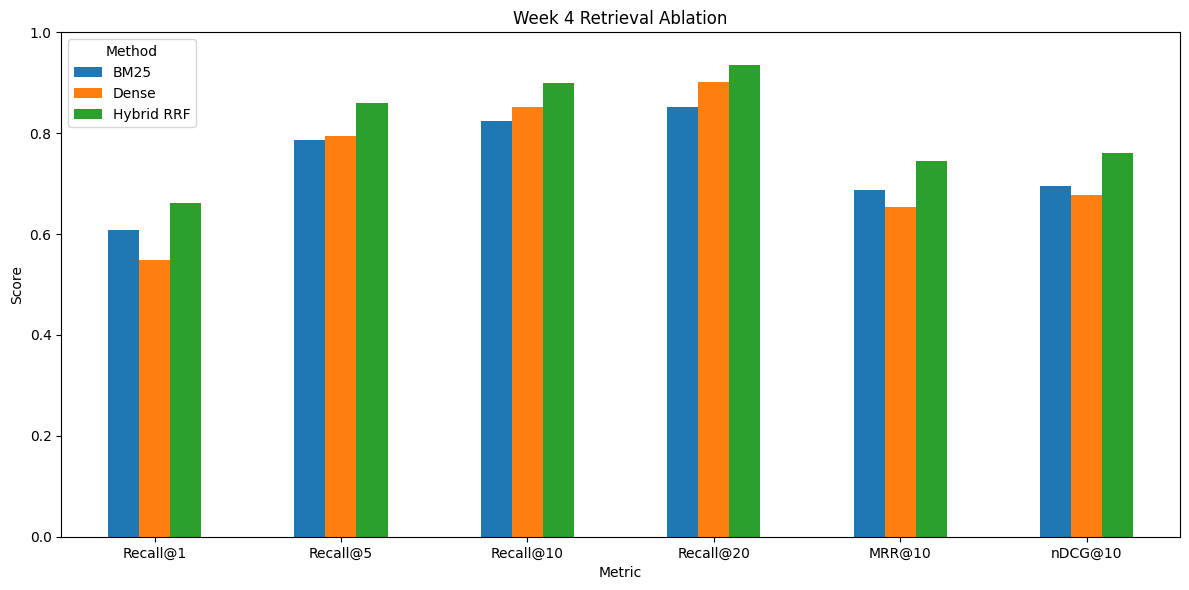

In [19]:
plot_metrics = [
    "Recall@1", "Recall@5", "Recall@10",
    "Recall@20", "MRR@10", "nDCG@10",
]
plot_df = ablation_df.set_index("method")[plot_metrics].T
ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
)
ax.set_title("Week 4 Retrieval Ablation")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.legend(title="Method", loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    artifact_dir / "week4_day3_retrieval_ablation.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [20]:
hybrid_candidate_records = []
for query_index, retrieved in enumerate(hybrid_indices[:, :RETRIEVAL_K]):
    relevant = relevant_sets[query_index]
    sparse_rank_map = {
        int(chunk_id): rank
        for rank, chunk_id in enumerate(bm25_indices[query_index], start=1)
    }
    dense_rank_map = {
        int(chunk_id): rank
        for rank, chunk_id in enumerate(dense_indices[query_index], start=1)
    }
    sparse_score_map = {
        int(chunk_id): float(score)
        for chunk_id, score in zip(
            bm25_indices[query_index],
            bm25_scores[query_index],
        )
    }
    dense_score_map = {
        int(chunk_id): float(score)
        for chunk_id, score in zip(
            dense_indices[query_index],
            dense_scores[query_index],
        )
    }

    for hybrid_rank, chunk_id in enumerate(retrieved, start=1):
        chunk_id = int(chunk_id)
        chunk = chunk_df.iloc[chunk_id]
        hybrid_candidate_records.append({
            "query_id": query_df.iloc[query_index]["query_id"],
            "question": query_df.iloc[query_index]["question"],
            "chunk_id": chunk_id,
            "title": chunk["title"],
            "context_index": int(chunk["context_index"]),
            "chunk_text": chunk["chunk_text"],
            "label": int(chunk_id in relevant),
            "hybrid_rank": hybrid_rank,
            "rrf_score": float(hybrid_scores[query_index, hybrid_rank - 1]),
            "bm25_rank": sparse_rank_map.get(chunk_id),
            "bm25_score": sparse_score_map.get(chunk_id),
            "dense_rank": dense_rank_map.get(chunk_id),
            "dense_score": dense_score_map.get(chunk_id),
        })

hybrid_candidate_df = pd.DataFrame(hybrid_candidate_records)
hybrid_candidate_df.to_csv(
    artifact_dir / "week4_day3_hybrid_top20_candidates.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Hybrid candidate rows:", len(hybrid_candidate_df))
print("Queries:", hybrid_candidate_df["query_id"].nunique())
print("Relevant candidates:", int(hybrid_candidate_df["label"].sum()))
display(hybrid_candidate_df.head(10))

Hybrid candidate rows: 20000
Queries: 1000
Relevant candidates: 1065


,query_id,question,chunk_id,title,context_index,chunk_text,label,hybrid_rank,rrf_score,bm25_rank,bm25_score,dense_rank,dense_score
0,6589969-27-0,이명박은 언제 취임식을 가졌는가?,1610,이명박,270,2008년 2월 25일 이명박은 취임식과 함께 업무 수행을 시작했다. 새 정부의 이...,1,1,0.030282,12.0,5.604052,1.0,0.591899
1,6589969-27-0,이명박은 언제 취임식을 가졌는가?,1614,이명박,271,그러나 이명박은 첫판부터 위기를 맞이하게 된다. 당시 논란이 된 광우병 쇠고기 문제...,0,2,0.028175,10.0,5.692839,12.0,0.452913
2,6589969-27-0,이명박은 언제 취임식을 가졌는가?,1621,이명박,272,"군사 경계지역을 침범하였다는 주장을 하고 있으나, 대한민국에서 요구하고 있는 진상규...",0,3,0.027347,6.0,6.290850,22.0,0.434381
3,6589969-27-0,이명박은 언제 취임식을 가졌는가?,1622,이명박,272,"이명박은 사건 당일 오후에 사건을 보고받았음에도 불구, 예정대로 대북 포용적인 내용...",0,4,0.024837,11.0,5.692839,33.0,0.421088
4,6589969-27-0,이명박은 언제 취임식을 가졌는가?,1501,이명박,249,1996년 4월 11일 치뤄진 15대 총선에서 이명박은 종로 지역구에 출마했다.정치...,0,5,0.016393,1.0,9.042193,NaN,NaN
5,6589969-27-0,이명박은 언제 취임식을 가졌는가?,3904,구리야마_히데키,631,오프에는 병원에 장기간 입원하면서 스프링 캠프에도 참가하지 못했고 언제 이 병이 재...,0,6,0.016129,2.0,7.308825,NaN,NaN
6,6589969-27-0,이명박은 언제 취임식을 가졌는가?,1538,이명박,257,"2008년 2월 25일에 취임식이 '함께 가요, 국민성공시대!' 라는 표어를 내걸고...",0,7,0.016129,NaN,NaN,2.0,0.557047
7,6589969-27-0,이명박은 언제 취임식을 가졌는가?,1723,이명박,288,많아졌고 이는 이명박의 대중 인기 증가에 큰 보탬이 되었다. 이에 힘입어 이명박은 ...,0,8,0.015873,3.0,6.894372,NaN,NaN
8,6589969-27-0,이명박은 언제 취임식을 가졌는가?,1611,이명박,270,실명을 공식적으로 정권 이름에 사용하게 되었다(이것이 첫 사례였다). 이명박 대통령...,0,9,0.015873,NaN,NaN,3.0,0.486706
9,6589969-27-0,이명박은 언제 취임식을 가졌는가?,1528,이명박,254,", 그 결과 10월 초 55.4%라는 높은 지지율을 기록했다. 그는 여론조사에서 1...",0,10,0.015625,4.0,6.519119,NaN,NaN


In [21]:
hybrid_case_records = []
for query_index, relevant in enumerate(relevant_sets):
    bm25_hit = any(
        int(idx) in relevant
        for idx in bm25_indices[query_index, :10]
    )
    dense_hit = any(
        int(idx) in relevant
        for idx in dense_indices[query_index, :10]
    )
    hybrid_hit = any(
        int(idx) in relevant
        for idx in hybrid_indices[query_index, :10]
    )
    if hybrid_hit and not bm25_hit and not dense_hit:
        case_type = "hybrid_only_recovery"
    elif hybrid_hit and not bm25_hit:
        case_type = "dense_contribution"
    elif hybrid_hit and not dense_hit:
        case_type = "bm25_contribution"
    elif not hybrid_hit:
        case_type = "hybrid_failure"
    else:
        case_type = "shared_success"
    hybrid_case_records.append({
        "query_id": query_df.iloc[query_index]["query_id"],
        "question": query_df.iloc[query_index]["question"],
        "bm25_hit_at_10": bm25_hit,
        "dense_hit_at_10": dense_hit,
        "hybrid_hit_at_10": hybrid_hit,
        "case_type": case_type,
    })

hybrid_case_df = pd.DataFrame(hybrid_case_records)
hybrid_case_df.to_csv(
    artifact_dir / "week4_day3_hybrid_case_analysis.csv",
    index=False,
    encoding="utf-8-sig",
)
display(
    hybrid_case_df["case_type"]
    .value_counts()
    .rename_axis("case_type")
    .reset_index(name="query_count")
)

,case_type,query_count
0,shared_success,742
1,hybrid_failure,100
2,dense_contribution,80
3,bm25_contribution,69
4,hybrid_only_recovery,9


In [22]:
retrieval_results = {
    "seed": SEED,
    "query_count": len(query_df),
    "context_count": len(context_records),
    "chunk_count": len(chunk_df),
    "chunk_token_size": CHUNK_TOKEN_SIZE,
    "chunk_token_overlap": CHUNK_TOKEN_OVERLAP,
    "candidate_k": CANDIDATE_K,
    "retrieval_k": RETRIEVAL_K,
    "rrf_k": RRF_K,
    "bm25": bm25_metrics,
    "dense": dense_metrics,
    "hybrid_rrf": hybrid_metrics,
    "latency_ms_per_query": {
        "bm25": bm25_latency_ms,
        "dense_encoding": dense_encoding_ms,
        "dense_search": dense_search_ms,
        "rrf_fusion": hybrid_fusion_ms,
    },
}
with (artifact_dir / "week4_day1_3_metrics.json").open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        retrieval_results,
        file,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

ablation_df.to_csv(
    artifact_dir / "week4_day3_ablation.csv",
    index=False,
)

artifact_manifest = {
    "week2_checkpoint": str(week2_checkpoint_path),
    "week2_config": str(week2_config_path),
    "week2_tokenizer": str(week2_tokenizer_dir),
    "week3_reranker": str(week3_model_dir),
    "output_directory": str(artifact_dir),
}
with (artifact_dir / "artifact_manifest.json").open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        artifact_manifest,
        file,
        ensure_ascii=False,
        indent=2,
    )

required_artifacts = [
    "week4_knowledge_base_chunks.csv",
    "week4_evaluation_queries.csv",
    "week4_dense_corpus_embeddings.npy",
    "week4_dense.index",
    "week4_bm25.pkl",
    "week4_day2_retrieval_comparison.csv",
    "week4_day3_hybrid_top20_candidates.csv",
    "week4_day3_hybrid_case_analysis.csv",
    "week4_day1_3_metrics.json",
    "week4_day3_retrieval_ablation.png",
]
missing_artifacts = [
    name
    for name in required_artifacts
    if not (artifact_dir / name).exists()
]
if missing_artifacts:
    raise FileNotFoundError(
        f"Missing Week 4 artifacts: {missing_artifacts}"
    )

zip_path = shutil.make_archive(
    "/kaggle/working/week4_day1_3_artifacts",
    "zip",
    artifact_dir,
)
print("Artifact verification passed")
print("Artifact directory:", artifact_dir)
print("ZIP path:", zip_path)

Artifact verification passed
Artifact directory: /kaggle/working/week4_day1_3_artifacts
ZIP path: /kaggle/working/week4_day1_3_artifacts.zip


# Day 3 Experiment Log

Validated RRF hybrid retrieval before reranking.


# Day 4 - Hybrid Top-20 Cross-Encoder Reranking

Rerank hybrid candidates with the Week 3 Cross-Encoder.


In [23]:
# 리랭커 실행 준비
RERANK_TOP_K = RETRIEVAL_K
RERANKER_BATCH_SIZE = 64

week2_parameter_count = int(
    sum(parameter.numel() for parameter in week2_model.parameters())
)
week2_model.to("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(device)

week3_tokenizer = AutoTokenizer.from_pretrained(
    week3_model_dir,
    local_files_only=True,
)
week3_reranker = AutoModelForSequenceClassification.from_pretrained(
    week3_model_dir,
    local_files_only=True,
).to(device)
week3_reranker.eval()

reranker_parameter_count = int(
    sum(parameter.numel() for parameter in week3_reranker.parameters())
)
print("Reranker candidate depth:", RERANK_TOP_K)
print("Reranker parameters:", f"{reranker_parameter_count:,}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Reranker candidate depth: 20
Reranker parameters: 110,619,650


In [24]:
def score_cross_encoder(questions, contexts, batch_size=64):
    if len(questions) != len(contexts):
        raise ValueError("Questions and contexts must have the same length.")

    scores = []
    for start in range(0, len(questions), batch_size):
        batch = week3_tokenizer(
            questions[start:start + batch_size],
            contexts[start:start + batch_size],
            padding=True,
            truncation="only_second",
            max_length=512,
            return_tensors="pt",
        )
        batch = {
            key: value.to(device)
            for key, value in batch.items()
        }
        with torch.inference_mode():
            logits = week3_reranker(**batch).logits
        if logits.shape[-1] != 2:
            raise ValueError("The Week 3 reranker must have two labels.")
        scores.extend(
            torch.softmax(logits, dim=-1)[:, 1]
            .detach()
            .cpu()
            .tolist()
        )
    return np.asarray(scores, dtype=np.float32)


hybrid_top20_indices = hybrid_indices[:, :RERANK_TOP_K]
pair_questions = []
pair_contexts = []
for query_index, question in enumerate(query_df["question"]):
    for chunk_id in hybrid_top20_indices[query_index]:
        pair_questions.append(question)
        pair_contexts.append(
            chunk_df.iloc[int(chunk_id)]["chunk_text"]
        )

if torch.cuda.is_available():
    torch.cuda.synchronize()
reranker_start = time.perf_counter()
flat_reranker_scores = score_cross_encoder(
    pair_questions,
    pair_contexts,
    batch_size=RERANKER_BATCH_SIZE,
)
if torch.cuda.is_available():
    torch.cuda.synchronize()
reranker_seconds = time.perf_counter() - reranker_start

reranker_scores = flat_reranker_scores.reshape(
    len(query_df),
    RERANK_TOP_K,
)
rerank_order = np.argsort(reranker_scores, axis=1)[:, ::-1]
reranked_indices = np.take_along_axis(
    hybrid_top20_indices,
    rerank_order,
    axis=1,
)
reranked_scores = np.take_along_axis(
    reranker_scores,
    rerank_order,
    axis=1,
)
reranked_metrics = evaluate_rankings(
    reranked_indices,
    relevant_sets,
)
reranker_latency_ms_per_query = (
    reranker_seconds / len(query_df) * 1000
)
reranker_peak_memory_mb = (
    torch.cuda.max_memory_allocated(device) / 1024 ** 2
    if torch.cuda.is_available()
    else 0.0
)

print("Hybrid + reranker metrics")
for name, value in reranked_metrics.items():
    if name in {
        "Recall@1", "Recall@5", "Recall@10", "Recall@20",
        "MRR@10", "nDCG@10",
    }:
        print(f"{name}: {value:.4f}")
print(
    "Reranker scoring per query:",
    f"{reranker_latency_ms_per_query:.3f} ms",
)
print("Reranker peak GPU memory:", f"{reranker_peak_memory_mb:.1f} MB")

Hybrid + reranker metrics
Recall@1: 0.6660
Recall@5: 0.9000
Recall@10: 0.9210
MRR@10: 0.7661
nDCG@10: 0.7835
Recall@20: 0.9350
Reranker scoring per query: 95.518 ms
Reranker peak GPU memory: 1097.4 MB


In [25]:
reranked_candidate_records = []
for query_index in range(len(query_df)):
    hybrid_rank_map = {
        int(chunk_id): rank
        for rank, chunk_id in enumerate(
            hybrid_top20_indices[query_index],
            start=1,
        )
    }
    relevant = relevant_sets[query_index]
    for rerank_rank, chunk_id in enumerate(
        reranked_indices[query_index],
        start=1,
    ):
        chunk_id = int(chunk_id)
        chunk = chunk_df.iloc[chunk_id]
        reranked_candidate_records.append({
            "query_id": query_df.iloc[query_index]["query_id"],
            "question": query_df.iloc[query_index]["question"],
            "answer_text": query_df.iloc[query_index]["answer_text"],
            "chunk_id": chunk_id,
            "title": chunk["title"],
            "chunk_text": chunk["chunk_text"],
            "label": int(chunk_id in relevant),
            "hybrid_rank": hybrid_rank_map[chunk_id],
            "rerank_rank": rerank_rank,
            "reranker_score": float(
                reranked_scores[query_index, rerank_rank - 1]
            ),
        })

reranked_candidate_df = pd.DataFrame(reranked_candidate_records)
reranked_candidate_df.to_csv(
    artifact_dir / "week4_day4_reranked_top20_candidates.csv",
    index=False,
    encoding="utf-8-sig",
)

day4_metrics = {
    "candidate_depth": RERANK_TOP_K,
    "hybrid_rrf": hybrid_metrics,
    "hybrid_reranked": reranked_metrics,
    "reranker_parameters": reranker_parameter_count,
    "reranker_latency_ms_per_query": reranker_latency_ms_per_query,
    "reranker_peak_gpu_memory_mb": reranker_peak_memory_mb,
}
with (artifact_dir / "week4_day4_reranker_metrics.json").open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(day4_metrics, file, ensure_ascii=False, indent=2)

day4_comparison_df = pd.DataFrame([
    {"method": "Hybrid RRF", **hybrid_metrics},
    {"method": "Hybrid + Reranker", **reranked_metrics},
])
display(day4_comparison_df[
    [
        "method", "Recall@1", "Recall@5", "Recall@10",
        "Recall@20", "MRR@10", "nDCG@10",
    ]
])
print("Saved reranked candidates:", len(reranked_candidate_df))

del week3_reranker
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

,method,Recall@1,Recall@5,Recall@10,Recall@20,MRR@10,nDCG@10
0,Hybrid RRF,0.662,0.859,0.900,0.935,0.745240,0.760423
1,Hybrid + Reranker,0.666,0.900,0.921,0.935,0.766101,0.783461


Saved reranked candidates: 20000


# Day 4 Experiment Log

Reranking improved Hybrid Recall@5 from 0.8590 to 0.9000, MRR@10 from 0.7452 to 0.7661, and nDCG@10 from 0.7604 to 0.7835. Recall@20 remained 0.9350 because the Hybrid Top-20 candidate set was fixed.


# Day 5 - Grounded Korean RAG Answer Generation

Compare grounded generation and extractive answer reading with citations.


In [26]:
# 생성 모델 설정
from transformers import AutoModelForCausalLM

GENERATION_MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
RAG_CONTEXT_K = 3
GENERATION_QUERY_LIMIT = 100
GENERATION_MAX_INPUT_TOKENS = 1024
GENERATION_MAX_NEW_TOKENS = 32
CORRECTION_MAX_NEW_TOKENS = 24

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(device)

generation_dtype = (
    torch.float16 if device.type == "cuda" else torch.float32
)
generator_tokenizer = AutoTokenizer.from_pretrained(
    GENERATION_MODEL_NAME,
)
if generator_tokenizer.pad_token_id is None:
    generator_tokenizer.pad_token = generator_tokenizer.eos_token

generator_model = AutoModelForCausalLM.from_pretrained(
    GENERATION_MODEL_NAME,
    dtype=generation_dtype,
).to(device)
generator_model.eval()
generator_model.generation_config.do_sample = False
generator_model.generation_config.temperature = None
generator_model.generation_config.top_p = None
generator_model.generation_config.top_k = None
generator_parameter_count = int(
    sum(parameter.numel() for parameter in generator_model.parameters())
)

print("Generation model:", GENERATION_MODEL_NAME)
print("Generator parameters:", f"{generator_parameter_count:,}")
print("Evidence chunks per answer:", RAG_CONTEXT_K)
print("Generation strategies: direct, question-focused, focused + validation")


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Generation model: Qwen/Qwen2.5-1.5B-Instruct
Generator parameters: 1,543,714,304
Evidence chunks per answer: 3
Generation strategies: direct, question-focused, focused + validation


In [27]:
def compact_match_text(text):
    return re.sub(
        r"[^0-9a-z가-힣]",
        "",
        normalize_text(text).lower(),
    )


def question_tokens(text):
    return set(re.findall(r"[가-힣A-Za-z0-9]+", normalize_text(text).lower()))


def split_evidence_units(text):
    units = re.split(r"(?<=[.!?])\s+|\n+", normalize_text(text))
    return [unit.strip() for unit in units if unit.strip()]


def select_question_focused_text(question, chunk_text, max_chars=420):
    units = split_evidence_units(chunk_text)
    if not units:
        return ""

    query_terms = question_tokens(question)
    scored_units = []
    for position, unit in enumerate(units):
        overlap = len(query_terms & question_tokens(unit))
        scored_units.append((overlap + 0.01 / (position + 1), position, unit))

    selected_positions = []
    selected_chars = 0
    for _, position, unit in sorted(scored_units, reverse=True):
        added_chars = len(unit) + (1 if selected_positions else 0)
        if selected_positions and selected_chars + added_chars > max_chars:
            continue
        selected_positions.append(position)
        selected_chars += added_chars
        if selected_chars >= max_chars:
            break

    selected_positions.sort()
    selected = " ".join(units[position] for position in selected_positions)
    return selected or normalize_text(chunk_text)[:max_chars]


def build_evidence_context(question, chunk_ids, question_focused=False, max_chars=1200):
    blocks = []
    remaining_chars = max_chars
    for evidence_rank, chunk_id in enumerate(chunk_ids, start=1):
        chunk = chunk_df.iloc[int(chunk_id)]
        raw_text = normalize_text(chunk["chunk_text"])
        if question_focused:
            snippet = select_question_focused_text(
                question,
                raw_text,
                max_chars=min(420, remaining_chars),
            )
        else:
            snippet = raw_text[:remaining_chars]
        snippet = snippet[:remaining_chars]
        if not snippet:
            continue
        blocks.append(
            f"[근거 {evidence_rank} | {chunk['title']} | chunk {int(chunk_id)}] {snippet}"
        )
        remaining_chars -= len(snippet)
        if remaining_chars <= 0:
            break
    return "\n\n".join(blocks)


def build_direct_prompt(question, evidence_context):
    system_message = (
        "당신은 한국어 질의응답 시스템입니다. 제공된 근거 문맥에 직접 "
        "적힌 정보만 사용하세요. 질문의 정답을 짧은 명사구, 날짜 또는 "
        "숫자로만 답하고, 질문을 다시 쓰거나 해설·추론·외부 지식·영어를 "
        "추가하지 마세요. 근거에서 답을 찾을 수 없으면 반드시 다음 문장만 "
        "출력하세요: 근거 문맥에서 답을 찾을 수 없습니다."
    )
    user_message = (
        f"질문: {question}\n\n"
        f"근거 문맥:\n{evidence_context}\n\n"
        "정답:"
    )
    messages = [
        {"role": "system", "content": system_message},
        {"role": "user", "content": user_message},
    ]
    if getattr(generator_tokenizer, "chat_template", None):
        return generator_tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )
    return f"{system_message}\n\n{user_message}"


def build_correction_prompt(question, evidence_context, draft_answer):
    system_message = (
        "당신은 근거 검증기입니다. 초안의 내용은 신뢰하지 말고, 제공된 "
        "근거 문맥에서 질문의 답으로 직접 복사할 수 있는 가장 짧은 문자열만 "
        "출력하세요. 설명, 문장부호, 영어, 추론을 추가하지 마세요. 근거에 "
        "답이 없으면 반드시 다음 문장만 출력하세요: 근거 문맥에서 답을 찾을 수 없습니다."
    )
    user_message = (
        f"질문: {question}\n\n"
        f"초안: {draft_answer}\n\n"
        f"근거 문맥:\n{evidence_context}\n\n"
        "근거에 있는 최종 답:"
    )
    messages = [
        {"role": "system", "content": system_message},
        {"role": "user", "content": user_message},
    ]
    if getattr(generator_tokenizer, "chat_template", None):
        return generator_tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True,
        )
    return f"{system_message}\n\n{user_message}"


def generate_text(prompt, max_new_tokens):
    model_inputs = generator_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=GENERATION_MAX_INPUT_TOKENS,
    )
    model_inputs = {key: value.to(device) for key, value in model_inputs.items()}
    input_length = model_inputs["input_ids"].shape[1]
    with torch.inference_mode():
        generated_ids = generator_model.generate(
            **model_inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=generator_tokenizer.pad_token_id,
            eos_token_id=generator_tokenizer.eos_token_id,
        )
    return generator_tokenizer.decode(
        generated_ids[0, input_length:],
        skip_special_tokens=True,
    ).strip()


def clean_answer(answer):
    answer = normalize_text(answer)
    answer = re.sub(r"^(정답|답변|최종 답|최종 답변)\s*[:：]\s*", "", answer)
    answer = answer.split("\n")[0].strip().strip("'\"“”")
    return answer or "근거 문맥에서 답을 찾을 수 없습니다."


def answer_is_grounded(answer, chunk_ids):
    compact_answer = compact_match_text(answer)
    if len(compact_answer) < 2 or "근거문맥에서답을찾을수없습니다" in compact_answer:
        return False
    return any(
        compact_answer in compact_match_text(chunk_df.iloc[int(chunk_id)]["chunk_text"])
        for chunk_id in chunk_ids
    )


def build_answer_citations(answer, chunk_ids):
    compact_answer = compact_match_text(answer)
    citations = []
    if len(compact_answer) < 2:
        return citations
    for evidence_rank, chunk_id in enumerate(chunk_ids, start=1):
        chunk = chunk_df.iloc[int(chunk_id)]
        if compact_answer in compact_match_text(chunk["chunk_text"]):
            citations.append({
                "evidence_rank": evidence_rank,
                "chunk_id": int(chunk_id),
                "title": str(chunk["title"]),
            })
    return citations


In [28]:
generation_query_indices = (
    query_df.sample(
        n=min(GENERATION_QUERY_LIMIT, len(query_df)),
        random_state=SEED,
    )
    .index
    .tolist()
)

if torch.cuda.is_available():
    torch.cuda.synchronize()
generation_start = time.perf_counter()
baseline_generation_seconds = 0.0
focused_generation_seconds = 0.0
correction_generation_seconds = 0.0
generation_run_records = []
rag_example_records = []

for query_index in generation_query_indices:
    row = query_df.iloc[query_index]
    top_chunk_ids = reranked_indices[query_index, :RAG_CONTEXT_K]
    raw_evidence_context = build_evidence_context(
        row["question"],
        top_chunk_ids,
        question_focused=False,
    )
    focused_evidence_context = build_evidence_context(
        row["question"],
        top_chunk_ids,
        question_focused=True,
    )
    compact_gold = compact_match_text(row["answer_text"])

    start = time.perf_counter()
    baseline_answer = clean_answer(generate_text(
        build_direct_prompt(row["question"], raw_evidence_context),
        GENERATION_MAX_NEW_TOKENS,
    ))
    baseline_generation_seconds += time.perf_counter() - start

    start = time.perf_counter()
    focused_draft = clean_answer(generate_text(
        build_direct_prompt(row["question"], focused_evidence_context),
        GENERATION_MAX_NEW_TOKENS,
    ))
    focused_generation_seconds += time.perf_counter() - start

    draft_is_grounded = answer_is_grounded(focused_draft, top_chunk_ids)
    correction_used = not draft_is_grounded
    final_answer = focused_draft
    if correction_used:
        start = time.perf_counter()
        corrected_answer = clean_answer(generate_text(
            build_correction_prompt(
                row["question"],
                focused_evidence_context,
                focused_draft,
            ),
            CORRECTION_MAX_NEW_TOKENS,
        ))
        correction_generation_seconds += time.perf_counter() - start
        if answer_is_grounded(corrected_answer, top_chunk_ids):
            final_answer = corrected_answer
        else:
            final_answer = "근거 문맥에서 답을 찾을 수 없습니다."

    strategy_rows = [
        ("Direct Top-3", baseline_answer, raw_evidence_context, False),
        ("Question-Focused Top-3", focused_draft, focused_evidence_context, False),
        ("Focused + Validation", final_answer, focused_evidence_context, correction_used),
    ]
    for strategy, answer, evidence_context, used_correction in strategy_rows:
        generation_run_records.append({
            "strategy": strategy,
            "query_index": int(query_index),
            "query_id": row["query_id"],
            "question": row["question"],
            "gold_answer": row["answer_text"],
            "generated_answer": answer,
            "gold_answer_in_context": bool(
                compact_gold and compact_gold in compact_match_text(evidence_context)
            ),
            "gold_answer_in_generated_answer": bool(
                compact_gold and compact_gold in compact_match_text(answer)
            ),
            "answer_is_grounded": answer_is_grounded(answer, top_chunk_ids),
            "correction_used": used_correction,
        })

    citations = build_answer_citations(final_answer, top_chunk_ids)
    rag_example_records.append({
        "query_index": int(query_index),
        "query_id": row["query_id"],
        "question": row["question"],
        "gold_answer": row["answer_text"],
        "draft_answer": focused_draft,
        "generated_answer": final_answer,
        "gold_answer_in_top3_context": bool(
            compact_gold and compact_gold in compact_match_text(focused_evidence_context)
        ),
        "gold_answer_in_generated_answer": bool(
            compact_gold and compact_gold in compact_match_text(final_answer)
        ),
        "answer_is_grounded": answer_is_grounded(final_answer, top_chunk_ids),
        "correction_used": correction_used,
        "citation_count": len(citations),
        "citations": json.dumps(citations, ensure_ascii=False),
        "reranked_chunk_ids": json.dumps([int(chunk_id) for chunk_id in top_chunk_ids]),
        "evidence_context": focused_evidence_context,
    })

if torch.cuda.is_available():
    torch.cuda.synchronize()
generation_seconds = time.perf_counter() - generation_start

generation_run_df = pd.DataFrame(generation_run_records)
rag_generation_df = pd.DataFrame(rag_example_records)
generation_strategy_summary_df = (
    generation_run_df.groupby("strategy", sort=False)
    .agg(
        query_count=("query_id", "count"),
        evidence_answer_coverage=("gold_answer_in_context", "mean"),
        generated_answer_coverage=("gold_answer_in_generated_answer", "mean"),
        grounded_answer_rate=("answer_is_grounded", "mean"),
        correction_rate=("correction_used", "mean"),
    )
    .reset_index()
)
strategy_latency_seconds = {
    "Direct Top-3": baseline_generation_seconds / len(generation_query_indices),
    "Question-Focused Top-3": focused_generation_seconds / len(generation_query_indices),
    "Focused + Validation": (
        focused_generation_seconds + correction_generation_seconds
    ) / len(generation_query_indices),
}
generation_strategy_summary_df["seconds_per_query"] = generation_strategy_summary_df[
    "strategy"
].map(strategy_latency_seconds)

generation_run_df.to_csv(
    artifact_dir / "week4_day5_generation_strategy_examples.csv",
    index=False,
    encoding="utf-8-sig",
)
rag_generation_df.to_csv(
    artifact_dir / "week4_day5_rag_examples.csv",
    index=False,
    encoding="utf-8-sig",
)
generation_metrics = {
    "generation_model": GENERATION_MODEL_NAME,
    "generation_query_count": len(rag_generation_df),
    "context_k": RAG_CONTEXT_K,
    "evidence_answer_coverage": float(
        rag_generation_df["gold_answer_in_top3_context"].mean()
    ),
    "generated_answer_coverage": float(
        rag_generation_df["gold_answer_in_generated_answer"].mean()
    ),
    "grounded_answer_rate": float(rag_generation_df["answer_is_grounded"].mean()),
    "citation_coverage": float((rag_generation_df["citation_count"] > 0).mean()),
    "correction_rate": float(rag_generation_df["correction_used"].mean()),
    "generation_seconds_per_query": strategy_latency_seconds["Focused + Validation"],
    "total_generation_experiment_seconds": generation_seconds,
    "generator_parameters": generator_parameter_count,
    "generator_peak_gpu_memory_mb": (
        torch.cuda.max_memory_allocated(device) / 1024 ** 2
        if torch.cuda.is_available()
        else 0.0
    ),
}
with (artifact_dir / "week4_day5_generation_metrics.json").open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(generation_metrics, file, ensure_ascii=False, indent=2)

display(generation_strategy_summary_df)
display(rag_generation_df[
    [
        "question", "gold_answer", "draft_answer", "generated_answer",
        "gold_answer_in_top3_context", "gold_answer_in_generated_answer",
        "answer_is_grounded", "correction_used", "citations",
    ]
].head(10))
print("Final evidence answer coverage:", f"{generation_metrics['evidence_answer_coverage']:.4f}")
print("Final generated answer coverage:", f"{generation_metrics['generated_answer_coverage']:.4f}")
print("Final grounded answer rate:", f"{generation_metrics['grounded_answer_rate']:.4f}")
print("Final citation coverage:", f"{generation_metrics['citation_coverage']:.4f}")
print("Final generation seconds per query:", f"{generation_metrics['generation_seconds_per_query']:.3f}")

del generator_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


,strategy,query_count,evidence_answer_coverage,generated_answer_coverage,grounded_answer_rate,correction_rate,seconds_per_query
0,Direct Top-3,100,0.89,0.55,0.74,0.00,0.421571
1,Question-Focused Top-3,100,0.89,0.55,0.74,0.00,0.416657
2,Focused + Validation,100,0.89,0.56,0.85,0.26,0.541370


,question,gold_answer,draft_answer,generated_answer,gold_answer_in_top3_context,gold_answer_in_generated_answer,answer_is_grounded,correction_used,citations
0,우드로 윌슨의 논문 행정의 연구가 발표된 해는?,1887년,1887년,1887년,True,True,True,False,"[{""evidence_rank"": 2, ""chunk_id"": 1211, ""title..."
1,3천명의 사상자를 내며 우세를 점한 군대는?,골리친의 군대,러시아_원정 | chunk 5819,근거 문맥에서 답을 찾을 수 없습니다.,True,False,False,True,[]
2,"뇌 자체에는 거의 손상을 입히지 않으나, 일시적인 뇌의 기능장애를 일으켜 사망에 이...",광견병,밀워키_프로토콜 | chunk 5712 | 2005년,근거 문맥에서 답을 찾을 수 없습니다.,True,False,False,True,[]
3,블루스가 남부 텍사스와 미국남부에서 기록되기 시작한 시기는?,20세기 초,19세기 초,근거 문맥에서 답을 찾을 수 없습니다.,True,False,False,True,[]
4,IPS의 미국 검찰진이 작성한 A급 전범 명단에는 몇 명이 올랐나?,30명,30,30,True,False,True,False,"[{""evidence_rank"": 1, ""chunk_id"": 4884, ""title..."
5,소토마요르가 부상을 당해 부진하게 된 년도는?,1996년,1996년,1996년,True,True,True,False,"[{""evidence_rank"": 1, ""chunk_id"": 395, ""title""..."
6,강정호를 한국 최고의 유격수라고 칭찬한 메이저리그 500홈런 타자는?,게리 셰필드,메이저리그 500홈런 타자 게리 셰필드,메이저리그 500홈런 타자 게리 셰필드,True,True,True,False,"[{""evidence_rank"": 1, ""chunk_id"": 4103, ""title..."
7,중국에서 구법이란 어떤 시대의 법령을 말하는가?,국민당,1949년,1949년,True,False,True,False,"[{""evidence_rank"": 1, ""chunk_id"": 3722, ""title..."
8,남북조의 통일 이후 모두 북조의 후예가 된 곳은?,일본 황실,북조의 후예,북조의 후예,True,False,True,False,"[{""evidence_rank"": 1, ""chunk_id"": 5849, ""title..."
9,비젠에 남아있던 무네카게 쪽 세력은?,우라가미 가신 세력,비젠에 남아있던 무네카게 쪽 세력은 구 우라가미 가신이 선동한 소규모 �,구 우라가미 가신이 선동한 소규모 봉기,False,False,True,True,"[{""evidence_rank"": 3, ""chunk_id"": 4365, ""title..."


Final evidence answer coverage: 0.8900
Final generated answer coverage: 0.5600
Final grounded answer rate: 0.8500
Final citation coverage: 0.8500
Final generation seconds per query: 0.541


## Day 5 Extension - Extractive QA Reader

The grounded Qwen experiments above remain the generative RAG baseline. This extension adds a Korean KorQuAD extractive QA Reader, applies it independently to each reranked Top-3 chunk, and selects the highest-confidence source span. The final reader-first answer falls back to the already validated Qwen response only if no usable Reader span is returned.


In [29]:
# 추출형 QA Reader 실행
from transformers import pipeline

EXTRACTIVE_READER_MODEL_NAME = "monologg/koelectra-base-v3-finetuned-korquad"
READER_MAX_ANSWER_TOKENS = 40
TARGET_ANSWER_COVERAGE = 0.60

reader_device = 0 if torch.cuda.is_available() else -1
qa_reader = pipeline(
    "question-answering",
    model=EXTRACTIVE_READER_MODEL_NAME,
    tokenizer=EXTRACTIVE_READER_MODEL_NAME,
    device=reader_device,
)
reader_parameter_count = int(
    sum(parameter.numel() for parameter in qa_reader.model.parameters())
)
print("Extractive Reader:", EXTRACTIVE_READER_MODEL_NAME)
print("Reader parameters:", f"{reader_parameter_count:,}")

reader_start = time.perf_counter()
reader_candidate_records = []
reader_final_records = []
reader_strategy_records = []

for _, previous_row in rag_generation_df.iterrows():
    query_index = int(previous_row["query_index"])
    top_chunk_ids = reranked_indices[query_index, :RAG_CONTEXT_K]
    gold_answer = str(previous_row["gold_answer"])
    compact_gold = compact_match_text(gold_answer)
    candidates = []
    for evidence_rank, chunk_id in enumerate(top_chunk_ids, start=1):
        chunk = chunk_df.iloc[int(chunk_id)]
        context = normalize_text(chunk["chunk_text"])
        result = qa_reader(
            question=str(previous_row["question"]),
            context=context,
            max_answer_len=READER_MAX_ANSWER_TOKENS,
            handle_impossible_answer=True,
        )
        answer = clean_answer(result.get("answer", ""))
        if len(compact_match_text(answer)) < 2:
            continue
        candidates.append({
            "answer": answer,
            "qa_score": float(result.get("score", 0.0)),
            "evidence_rank": evidence_rank,
            "chunk_id": int(chunk_id),
            "title": str(chunk["title"]),
        })
    candidates.sort(key=lambda candidate: candidate["qa_score"], reverse=True)
    for candidate_rank, candidate in enumerate(candidates[:5], start=1):
        reader_candidate_records.append({
            "query_index": query_index,
            "query_id": previous_row["query_id"],
            "question": previous_row["question"],
            "gold_answer": gold_answer,
            "candidate_rank": candidate_rank,
            **candidate,
            "is_gold_answer": bool(
                compact_gold and compact_gold in compact_match_text(candidate["answer"])
            ),
        })

    reader_answer = candidates[0]["answer"] if candidates else ""
    qwen_answer = str(previous_row["generated_answer"])
    if reader_answer:
        final_answer = reader_answer
        answer_source = "extractive_reader"
        reader_qa_score = candidates[0]["qa_score"]
    elif answer_is_grounded(qwen_answer, top_chunk_ids):
        final_answer = qwen_answer
        answer_source = "validated_qwen_fallback"
        reader_qa_score = np.nan
    else:
        final_answer = "근거 문맥에서 답을 찾을 수 없습니다."
        answer_source = "abstained"
        reader_qa_score = np.nan

    citations = build_answer_citations(final_answer, top_chunk_ids)
    final_record = previous_row.to_dict()
    final_record.update({
        "qwen_validated_answer": qwen_answer,
        "reader_answer": reader_answer or "근거 문맥에서 답을 찾을 수 없습니다.",
        "generated_answer": final_answer,
        "answer_source": answer_source,
        "reader_qa_score": reader_qa_score,
        "gold_answer_in_generated_answer": bool(
            compact_gold and compact_gold in compact_match_text(final_answer)
        ),
        "answer_is_grounded": answer_is_grounded(final_answer, top_chunk_ids),
        "citation_count": len(citations),
        "citations": json.dumps(citations, ensure_ascii=False),
    })
    reader_final_records.append(final_record)

    for strategy, answer, source in [
        ("Extractive QA Reader", reader_answer, "extractive_reader"),
        ("Reader-First Final Answer", final_answer, answer_source),
    ]:
        reader_strategy_records.append({
            "strategy": strategy,
            "query_index": query_index,
            "query_id": previous_row["query_id"],
            "question": previous_row["question"],
            "gold_answer": gold_answer,
            "generated_answer": answer,
            "gold_answer_in_context": previous_row["gold_answer_in_top3_context"],
            "gold_answer_in_generated_answer": bool(
                compact_gold and compact_gold in compact_match_text(answer)
            ),
            "answer_is_grounded": answer_is_grounded(answer, top_chunk_ids),
            "correction_used": False,
            "answer_source": source,
        })

reader_seconds = time.perf_counter() - reader_start
reader_strategy_df = pd.DataFrame(reader_strategy_records)
generation_run_df = pd.concat([generation_run_df, reader_strategy_df], ignore_index=True)
rag_generation_df = pd.DataFrame(reader_final_records)
generation_strategy_summary_df = (
    generation_run_df.groupby("strategy", sort=False)
    .agg(
        query_count=("query_id", "count"),
        evidence_answer_coverage=("gold_answer_in_context", "mean"),
        generated_answer_coverage=("gold_answer_in_generated_answer", "mean"),
        grounded_answer_rate=("answer_is_grounded", "mean"),
        correction_rate=("correction_used", "mean"),
    ).reset_index()
)
strategy_latency_seconds["Extractive QA Reader"] = reader_seconds / len(rag_generation_df)
strategy_latency_seconds["Reader-First Final Answer"] = reader_seconds / len(rag_generation_df)
generation_strategy_summary_df["seconds_per_query"] = generation_strategy_summary_df["strategy"].map(strategy_latency_seconds)

generation_run_df.to_csv(artifact_dir / "week4_day5_generation_strategy_examples.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(reader_candidate_records).to_csv(artifact_dir / "week4_day5_reader_candidates.csv", index=False, encoding="utf-8-sig")
rag_generation_df.to_csv(artifact_dir / "week4_day5_rag_examples.csv", index=False, encoding="utf-8-sig")
generation_metrics.update({
    "extractive_reader_model": EXTRACTIVE_READER_MODEL_NAME,
    "reader_parameters": reader_parameter_count,
    "target_answer_coverage": TARGET_ANSWER_COVERAGE,
    "generated_answer_coverage": float(rag_generation_df["gold_answer_in_generated_answer"].mean()),
    "grounded_answer_rate": float(rag_generation_df["answer_is_grounded"].mean()),
    "citation_coverage": float((rag_generation_df["citation_count"] > 0).mean()),
    "generation_seconds_per_query": strategy_latency_seconds["Reader-First Final Answer"],
})
generation_metrics["target_coverage_met"] = bool(
    generation_metrics["generated_answer_coverage"] >= TARGET_ANSWER_COVERAGE
)
with (artifact_dir / "week4_day5_generation_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(generation_metrics, file, ensure_ascii=False, indent=2)

display(generation_strategy_summary_df)
display(rag_generation_df[[
    "question", "gold_answer", "qwen_validated_answer", "reader_answer",
    "generated_answer", "answer_source", "gold_answer_in_generated_answer", "citations",
]].head(10))
print("Final answer coverage:", f"{generation_metrics['generated_answer_coverage']:.4f}")
print("Target coverage met:", generation_metrics["target_coverage_met"])
print("Reader-first seconds per query:", f"{generation_metrics['generation_seconds_per_query']:.3f}")

del qa_reader
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


config.json:   0%|          | 0.00/591 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/449M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

ElectraForQuestionAnswering LOAD REPORT from: monologg/koelectra-base-v3-finetuned-korquad
Key                             | Status     |  | 
--------------------------------+------------+--+-
electra.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

...

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Extractive Reader: monologg/koelectra-base-v3-finetuned-korquad
Reader parameters: 112,332,290


,strategy,query_count,evidence_answer_coverage,generated_answer_coverage,grounded_answer_rate,correction_rate,seconds_per_query
0,Direct Top-3,100,0.89,0.55,0.74,0.00,0.421571
1,Question-Focused Top-3,100,0.89,0.55,0.74,0.00,0.416657
2,Focused + Validation,100,0.89,0.56,0.85,0.26,0.541370
3,Extractive QA Reader,100,0.89,0.64,0.85,0.00,0.031368
4,Reader-First Final Answer,100,0.89,0.64,0.85,0.00,0.031368


,question,gold_answer,qwen_validated_answer,reader_answer,generated_answer,answer_source,gold_answer_in_generated_answer,citations
0,우드로 윌슨의 논문 행정의 연구가 발표된 해는?,1887년,1887년,1887년,1887년,extractive_reader,True,"[{""evidence_rank"": 2, ""chunk_id"": 1211, ""title..."
1,3천명의 사상자를 내며 우세를 점한 군대는?,골리친의 군대,근거 문맥에서 답을 찾을 수 없습니다.,원정군의,원정군의,extractive_reader,False,"[{""evidence_rank"": 1, ""chunk_id"": 5748, ""title..."
2,"뇌 자체에는 거의 손상을 입히지 않으나, 일시적인 뇌의 기능장애를 일으켜 사망에 이...",광견병,근거 문맥에서 답을 찾을 수 없습니다.,광견병으로,광견병으로,extractive_reader,True,"[{""evidence_rank"": 1, ""chunk_id"": 5705, ""title..."
3,블루스가 남부 텍사스와 미국남부에서 기록되기 시작한 시기는?,20세기 초,근거 문맥에서 답을 찾을 수 없습니다.,19세기 말에,19세기 말에,extractive_reader,False,"[{""evidence_rank"": 3, ""chunk_id"": 2108, ""title..."
4,IPS의 미국 검찰진이 작성한 A급 전범 명단에는 몇 명이 올랐나?,30명,30,30명이,30명이,extractive_reader,True,"[{""evidence_rank"": 1, ""chunk_id"": 4884, ""title..."
5,소토마요르가 부상을 당해 부진하게 된 년도는?,1996년,1996년,1996년에,1996년에,extractive_reader,True,"[{""evidence_rank"": 1, ""chunk_id"": 395, ""title""..."
6,강정호를 한국 최고의 유격수라고 칭찬한 메이저리그 500홈런 타자는?,게리 셰필드,메이저리그 500홈런 타자 게리 셰필드,게리 셰필드로부터,게리 셰필드로부터,extractive_reader,True,"[{""evidence_rank"": 1, ""chunk_id"": 4103, ""title..."
7,중국에서 구법이란 어떤 시대의 법령을 말하는가?,국민당,1949년,국민당 시대의,국민당 시대의,extractive_reader,True,"[{""evidence_rank"": 1, ""chunk_id"": 3722, ""title..."
8,남북조의 통일 이후 모두 북조의 후예가 된 곳은?,일본 황실,북조의 후예,일본 황실은,일본 황실은,extractive_reader,True,"[{""evidence_rank"": 1, ""chunk_id"": 5849, ""title..."
9,비젠에 남아있던 무네카게 쪽 세력은?,우라가미 가신 세력,구 우라가미 가신이 선동한 소규모 봉기,구 우라가미 세력을,구 우라가미 세력을,extractive_reader,False,"[{""evidence_rank"": 1, ""chunk_id"": 4367, ""title..."


Final answer coverage: 0.6400
Target coverage met: True
Reader-first seconds per query: 0.031


# Day 5 Experiment Log

On the fixed 100-query sample, Qwen Focused + Validation reached answer coverage 0.56. The extractive Reader reached 0.64 with grounded-answer rate 0.85 and was selected for the final answer path.


# Day 6 - End-to-End Ablation, Efficiency, and Error Analysis

Compare end-to-end answer strategies, latency, and error cases.


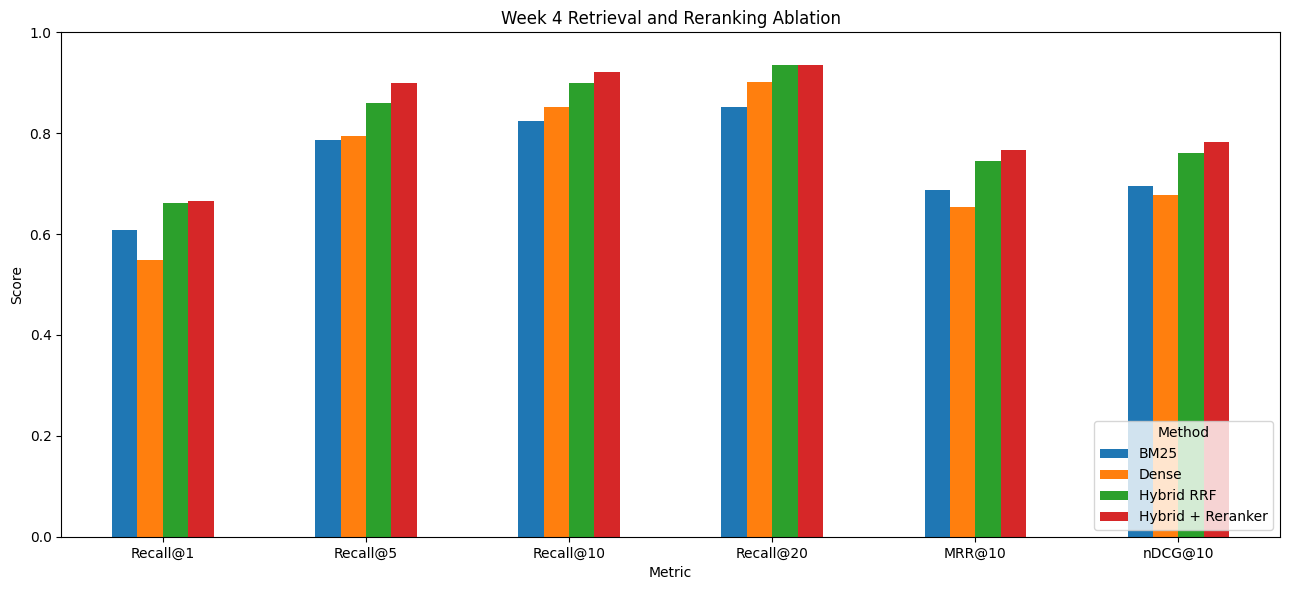

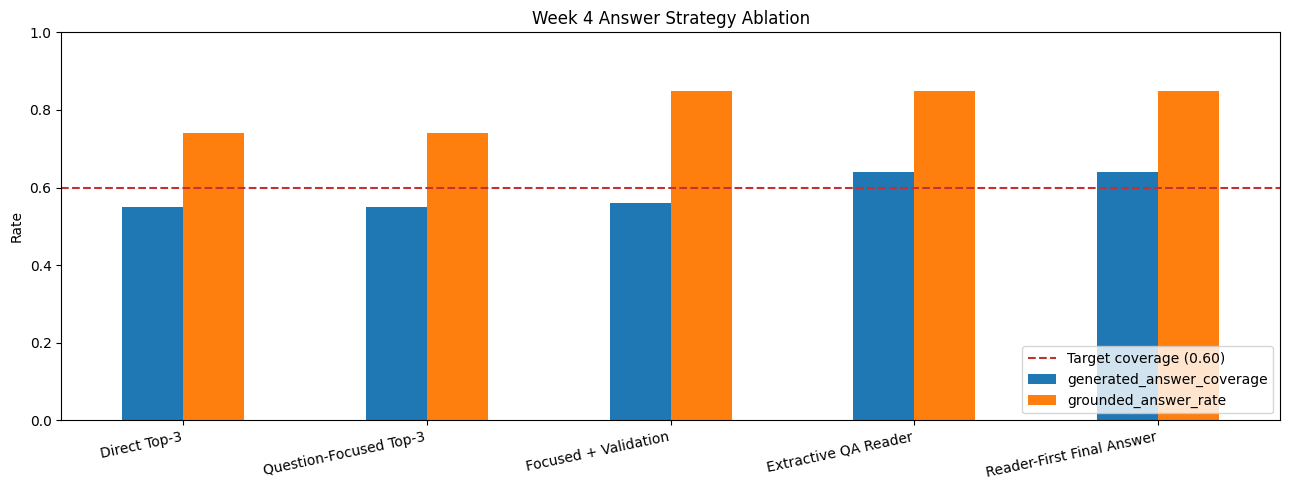

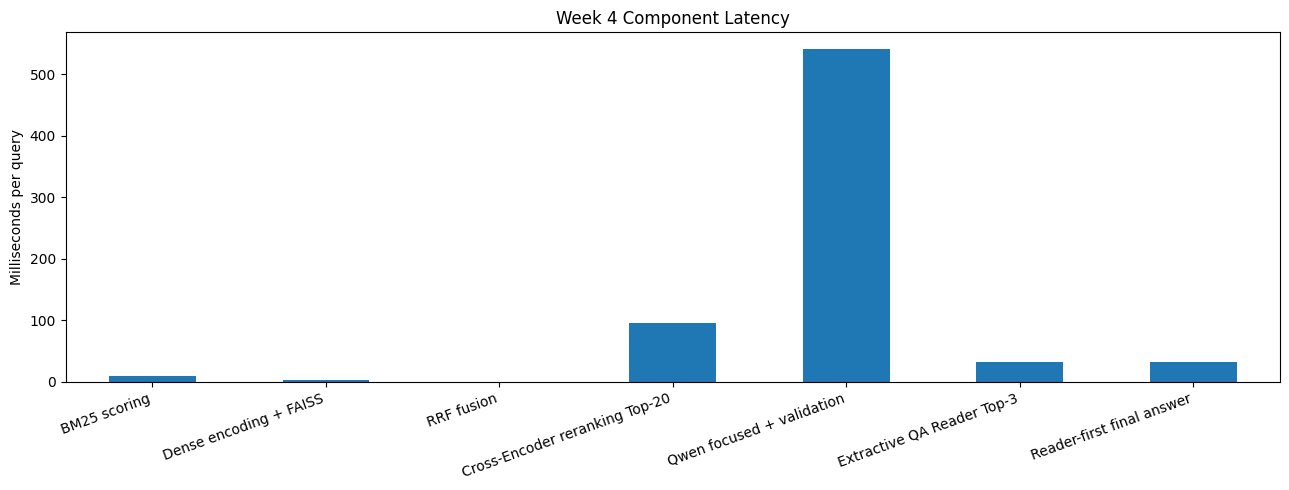

,method,Recall@1,MRR@1,nDCG@1,Recall@5,MRR@5,nDCG@5,Recall@10,MRR@10,nDCG@10,Recall@20,MRR@20,nDCG@20
0,BM25,0.609,0.609,0.609,0.786,0.681983,0.681550,0.824,0.686990,0.695750,0.851,0.688918,0.703420
1,Dense,0.549,0.549,0.549,0.795,0.645950,0.655142,0.851,0.653467,0.676733,0.901,0.656942,0.692082
2,Hybrid RRF,0.662,0.662,0.662,0.859,0.739550,0.743989,0.900,0.745240,0.760423,0.935,0.747838,0.771349
3,Hybrid + Reranker,0.666,0.666,0.666,0.900,0.763200,0.774469,0.921,0.766101,0.783461,0.935,0.767084,0.788640


,stage,evaluation_scope,evidence_answer_coverage,generated_answer_coverage,grounded_answer_rate,citation_coverage,correction_rate,seconds_per_query
0,Hybrid + Reranker Top-3,"1,000 retrieval queries",0.854,NaN,NaN,NaN,NaN,NaN
1,Direct Top-3,100 fixed answer queries,0.890,0.55,0.74,NaN,0.00,0.421571
2,Question-Focused Top-3,100 fixed answer queries,0.890,0.55,0.74,NaN,0.00,0.416657
3,Focused + Validation,100 fixed answer queries,0.890,0.56,0.85,NaN,0.26,0.541370
4,Extractive QA Reader,100 fixed answer queries,0.890,0.64,0.85,NaN,0.00,0.031368
5,Reader-First Final Answer,100 fixed answer queries,0.890,0.64,0.85,0.85,0.00,0.031368


,metric,target,observed,target_met,evaluation_scope
0,Final normalized answer coverage,0.6,0.64,True,100 fixed answer queries


,error_category,query_count
0,answer_covered,64
1,reader_extraction_miss,25
2,retrieval_miss,11


In [30]:
reranked_top3_metrics = evaluate_rankings(
    reranked_indices[:, :RAG_CONTEXT_K],
    relevant_sets,
    cutoffs=(1, RAG_CONTEXT_K),
)

retrieval_ablation_df = pd.DataFrame([
    {"method": "BM25", **bm25_metrics},
    {"method": "Dense", **dense_metrics},
    {"method": "Hybrid RRF", **hybrid_metrics},
    {"method": "Hybrid + Reranker", **reranked_metrics},
])
retrieval_ablation_df.to_csv(
    artifact_dir / "week4_day6_retrieval_ablation.csv", index=False
)

generation_ablation_df = pd.concat([
    pd.DataFrame([{
        "stage": "Hybrid + Reranker Top-3",
        "evaluation_scope": "1,000 retrieval queries",
        "evidence_answer_coverage": reranked_top3_metrics[f"Recall@{RAG_CONTEXT_K}"],
        "generated_answer_coverage": np.nan,
        "grounded_answer_rate": np.nan,
        "citation_coverage": np.nan,
        "correction_rate": np.nan,
        "seconds_per_query": np.nan,
    }]),
    generation_strategy_summary_df.rename(columns={"strategy": "stage"}).assign(
        evaluation_scope=lambda frame: frame["query_count"].map(
            lambda count: f"{count} fixed answer queries"
        ),
        citation_coverage=lambda frame: np.where(
            frame["stage"] == "Reader-First Final Answer",
            generation_metrics["citation_coverage"],
            np.nan,
        ),
    )[[
        "stage", "evaluation_scope", "evidence_answer_coverage",
        "generated_answer_coverage", "grounded_answer_rate",
        "citation_coverage", "correction_rate", "seconds_per_query",
    ]],
], ignore_index=True)
generation_ablation_df.to_csv(
    artifact_dir / "week4_day6_generation_ablation.csv", index=False
)
generation_strategy_summary_df.to_csv(
    artifact_dir / "week4_day6_generation_strategy_summary.csv", index=False
)

target_status_df = pd.DataFrame([{
    "metric": "Final normalized answer coverage",
    "target": TARGET_ANSWER_COVERAGE,
    "observed": generation_metrics["generated_answer_coverage"],
    "target_met": generation_metrics["target_coverage_met"],
    "evaluation_scope": f"{generation_metrics['generation_query_count']} fixed answer queries",
}])
target_status_df.to_csv(
    artifact_dir / "week4_day6_answer_target_status.csv", index=False
)

latency_df = pd.DataFrame([
    {"component": "BM25 scoring", "latency_ms_per_query": bm25_latency_ms},
    {
        "component": "Dense encoding + FAISS",
        "latency_ms_per_query": dense_encoding_ms + dense_search_ms,
    },
    {"component": "RRF fusion", "latency_ms_per_query": hybrid_fusion_ms},
    {
        "component": "Cross-Encoder reranking Top-20",
        "latency_ms_per_query": reranker_latency_ms_per_query,
    },
    {
        "component": "Qwen focused + validation",
        "latency_ms_per_query": strategy_latency_seconds["Focused + Validation"] * 1000,
    },
    {
        "component": "Extractive QA Reader Top-3",
        "latency_ms_per_query": strategy_latency_seconds["Extractive QA Reader"] * 1000,
    },
    {
        "component": "Reader-first final answer",
        "latency_ms_per_query": strategy_latency_seconds["Reader-First Final Answer"] * 1000,
    },
])
latency_df.to_csv(artifact_dir / "week4_day6_latency.csv", index=False)

parameter_df = pd.DataFrame([
    {
        "component": "Week 2 dense retriever",
        "parameter_count": week2_parameter_count,
        "peak_gpu_memory_mb": np.nan,
    },
    {
        "component": "Week 3 reranker",
        "parameter_count": reranker_parameter_count,
        "peak_gpu_memory_mb": reranker_peak_memory_mb,
    },
    {
        "component": "Qwen generator",
        "parameter_count": generator_parameter_count,
        "peak_gpu_memory_mb": generation_metrics["generator_peak_gpu_memory_mb"],
    },
    {
        "component": "KorQuAD extractive QA Reader",
        "parameter_count": reader_parameter_count,
        "peak_gpu_memory_mb": np.nan,
    },
])
parameter_df.to_csv(artifact_dir / "week4_day6_model_efficiency.csv", index=False)

def classify_reader_result(row):
    if not row["gold_answer_in_top3_context"]:
        return "retrieval_miss"
    if row["gold_answer_in_generated_answer"]:
        return "answer_covered"
    if row.get("answer_source") == "extractive_reader":
        return "reader_extraction_miss"
    if row["answer_is_grounded"]:
        return "grounded_llm_extraction_miss"
    return "unsupported_answer_rejected"


rag_generation_df["error_category"] = rag_generation_df.apply(
    classify_reader_result, axis=1
)
rag_error_summary_df = (
    rag_generation_df["error_category"].value_counts()
    .rename_axis("error_category").reset_index(name="query_count")
)
rag_error_examples_df = rag_generation_df.loc[
    rag_generation_df["error_category"] != "answer_covered",
    [
        "error_category", "query_id", "question", "gold_answer",
        "qwen_validated_answer", "reader_answer", "generated_answer",
        "answer_source", "citations", "evidence_context",
    ],
].head(30)
rag_error_summary_df.to_csv(
    artifact_dir / "week4_day6_rag_error_summary.csv", index=False
)
rag_error_examples_df.to_csv(
    artifact_dir / "week4_day6_rag_error_examples.csv",
    index=False, encoding="utf-8-sig"
)

comparison_metrics = [
    "Recall@1", "Recall@5", "Recall@10", "Recall@20", "MRR@10", "nDCG@10",
]
ax = retrieval_ablation_df.set_index("method")[comparison_metrics].T.plot(
    kind="bar", figsize=(13, 6), ylim=(0, 1)
)
ax.set_title("Week 4 Retrieval and Reranking Ablation")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.legend(title="Method", loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(artifact_dir / "week4_day6_retrieval_ablation.png", dpi=160, bbox_inches="tight")
plt.show()

generation_plot_df = generation_strategy_summary_df.set_index("strategy")[
    ["generated_answer_coverage", "grounded_answer_rate"]
]
ax = generation_plot_df.plot(kind="bar", figsize=(13, 5), ylim=(0, 1))
ax.axhline(
    TARGET_ANSWER_COVERAGE, color="#C53030", linestyle="--", linewidth=1.5,
    label=f"Target coverage ({TARGET_ANSWER_COVERAGE:.2f})",
)
ax.set_title("Week 4 Answer Strategy Ablation")
ax.set_ylabel("Rate")
ax.set_xlabel("")
ax.legend(loc="lower right")
plt.xticks(rotation=12, ha="right")
plt.tight_layout()
plt.savefig(artifact_dir / "week4_day6_generation_ablation.png", dpi=160, bbox_inches="tight")
plt.show()

ax = latency_df.plot(
    x="component", y="latency_ms_per_query", kind="bar", legend=False, figsize=(13, 5)
)
ax.set_title("Week 4 Component Latency")
ax.set_ylabel("Milliseconds per query")
ax.set_xlabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(artifact_dir / "week4_day6_latency.png", dpi=160, bbox_inches="tight")
plt.show()

display(retrieval_ablation_df)
display(generation_ablation_df)
display(target_status_df)
display(rag_error_summary_df)


# Day 6 Experiment Log

The final Reader-First strategy reached answer coverage 0.64, above the 0.60 target. The final error split was 64 covered answers, 25 reader extraction misses, and 11 retrieval misses.


# Day 7 - Portfolio Summary, Architecture, and Reproducible Packaging

Package final results, architecture files, and reproducible artifacts.


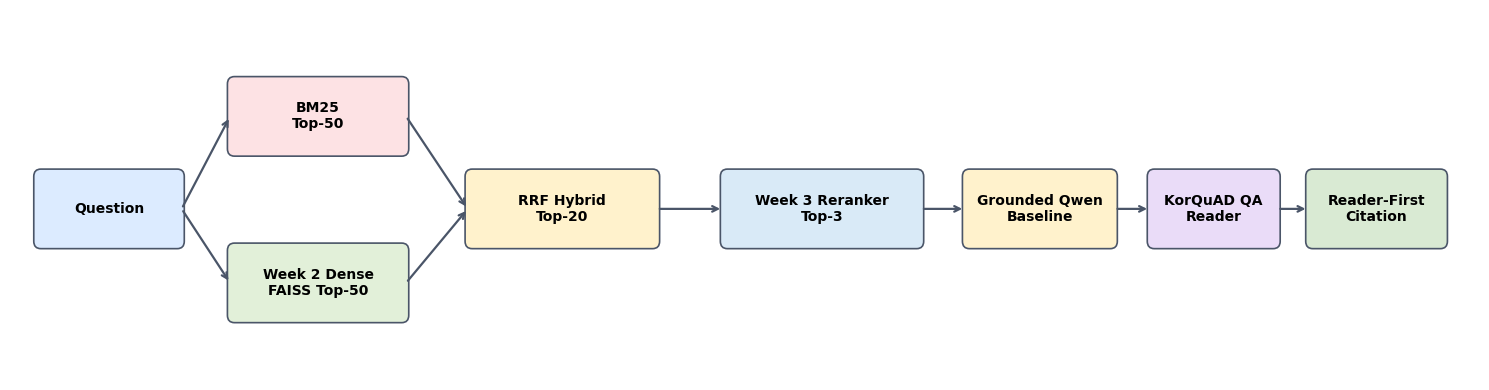

Final artifact verification passed
Final ZIP path: /kaggle/working/week4_final_artifacts.zip
Portfolio summary: /kaggle/working/week4_day1_3_artifacts/week4_portfolio_summary.md


In [31]:
from matplotlib.patches import FancyBboxPatch

architecture_mermaid = "\n".join([
    "flowchart LR",
    "    Q[KorQuAD Question] --> B[BM25 Top-50]",
    "    Q --> D[Week 2 Dense Retriever + FAISS Top-50]",
    "    B --> H[RRF Hybrid Top-20]",
    "    D --> H",
    "    H --> R[Week 3 Cross-Encoder Reranker Top-3]",
    "    R --> G[Grounded Qwen Answer]",
    "    R --> X[KorQuAD Extractive QA Reader]",
    "    G --> S[Reader-First Selector]",
    "    X --> S",
    "    S --> A[Answer with Citation]",
])
(artifact_dir / "week4_rag_architecture.mmd").write_text(
    architecture_mermaid,
    encoding="utf-8",
)

figure, axis = plt.subplots(figsize=(15, 4))
axis.set_xlim(0, 16.7)
axis.set_ylim(0, 4)
axis.axis("off")
architecture_boxes = [
    (0.3, 1.45, 1.65, 0.8, "Question", "#DCEBFF"),
    (2.5, 2.45, 2.0, 0.8, "BM25\nTop-50", "#FDE2E4"),
    (2.5, 0.65, 2.0, 0.8, "Week 2 Dense\nFAISS Top-50", "#E2F0D9"),
    (5.2, 1.45, 2.15, 0.8, "RRF Hybrid\nTop-20", "#FFF2CC"),
    (8.1, 1.45, 2.25, 0.8, "Week 3 Reranker\nTop-3", "#D9EAF7"),
    (10.85, 1.45, 1.7, 0.8, "Grounded Qwen\nBaseline", "#FFF2CC"),
    (12.95, 1.45, 1.45, 0.8, "KorQuAD QA\nReader", "#EADCF8"),
    (14.75, 1.45, 1.55, 0.8, "Reader-First\nCitation", "#D9EAD3"),
]
for x, y, width, height, label, color in architecture_boxes:
    axis.add_patch(FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        linewidth=1.2,
        edgecolor="#4A5568",
        facecolor=color,
    ))
    axis.text(
        x + width / 2,
        y + height / 2,
        label,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
    )
for start, end in [
    ((1.95, 1.85), (2.5, 2.85)),
    ((1.95, 1.85), (2.5, 1.05)),
    ((4.5, 2.85), (5.2, 1.85)),
    ((4.5, 1.05), (5.2, 1.85)),
    ((7.35, 1.85), (8.1, 1.85)),
    ((10.35, 1.85), (10.85, 1.85)),
    ((12.55, 1.85), (12.95, 1.85)),
    ((14.4, 1.85), (14.75, 1.85)),
]:
    axis.annotate(
        "",
        xy=end,
        xytext=start,
        arrowprops={"arrowstyle": "->", "lw": 1.6, "color": "#4A5568"},
    )
figure.tight_layout()
figure.savefig(
    artifact_dir / "week4_rag_architecture.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()


def dataframe_to_markdown(frame, columns):
    header = "| " + " | ".join(columns) + " |"
    separator = "| " + " | ".join(["---"] * len(columns)) + " |"
    rows = []
    for _, row in frame[columns].iterrows():
        values = []
        for column in columns:
            value = row[column]
            if isinstance(value, (float, np.floating)):
                values.append("-" if np.isnan(value) else f"{value:.4f}")
            else:
                values.append(str(value))
        rows.append("| " + " | ".join(values) + " |")
    return "\n".join([header, separator, *rows])


retrieval_table = dataframe_to_markdown(
    retrieval_ablation_df,
    ["method", "Recall@1", "Recall@5", "Recall@10", "Recall@20", "MRR@10", "nDCG@10"],
)
generation_table = dataframe_to_markdown(
    generation_ablation_df,
    ["stage", "evaluation_scope", "evidence_answer_coverage", "generated_answer_coverage"],
)
error_table = dataframe_to_markdown(
    rag_error_summary_df,
    ["error_category", "query_count"],
)
summary_markdown = "\n".join([
    "# Week 4 - Hybrid RAG and Quantitative Evaluation",
    "",
    "## Objective",
    "",
    "Build a Korean RAG pipeline by reusing the Week 2 dense retriever and Week 3 hard-negative Cross-Encoder reranker. The final system combines BM25, FAISS dense retrieval, Reciprocal Rank Fusion, cross-encoder reranking, grounded Korean Qwen generation, and a KorQuAD extractive QA Reader.",
    "",
    "## Reproducible inputs",
    "",
    "- Week 2: persisted dense retriever checkpoint, tokenizer, and retrieval configuration",
    "- Week 3: `week3_day4_final_reranker` checkpoint",
    f"- Extractive Reader: `{EXTRACTIVE_READER_MODEL_NAME}`",
    "- Dataset: KorQuAD v1 validation split; 1,000 fixed retrieval queries and 100 fixed answer queries",
    f"- Seed: {SEED}",
    "",
    "## Retrieval ablation",
    "",
    retrieval_table,
    "",
    "## Answer-strategy evaluation",
    "",
    generation_table,
    "",
    "The predefined final answer-coverage target is 0.60. Generated-answer coverage is a normalized gold-answer mention proxy. Grounded-answer rate measures whether the final answer text occurs in a reranked source chunk; citation coverage measures whether that match is surfaced to the user. These remain separate from retrieval metrics and should be complemented by manual review of the saved examples.",
    "",
    "## Key findings",
    "",
    "- RRF Hybrid retrieval provides the candidate set for reranking and is evaluated under the same query set as BM25 and Dense retrieval.",
    "- The Cross-Encoder changes only the order of Hybrid Top-20 candidates; its early-rank metrics therefore measure ranking quality without conflating candidate coverage.",
    f"- Qwen grounded generation and the KorQuAD extractive QA Reader receive the same reranked Top-{RAG_CONTEXT_K} evidence chunks.",
    "- The reader-first selector returns the highest-confidence source span and uses validated Qwen output only when no Reader span is available; accepted answers include chunk-level citations.",
    "- Remaining RAG failures are separated into retrieval misses, grounded extraction misses, and unsupported answers rejected after correction.",
    "",
    "## RAG error analysis",
    "",
    error_table,
    "",
    "## Architecture",
    "",
    "`Question -> BM25 Top-50 + Week 2 Dense FAISS Top-50 -> RRF Hybrid Top-20 -> Week 3 Cross-Encoder Top-3 -> Question-Focused Evidence -> Grounded Korean LLM -> Evidence Validation + Citation -> Answer`",
    "",
    "The accompanying `week4_rag_architecture.png` and `week4_rag_architecture.mmd` provide rendered and editable versions of this diagram.",
    "",
    "## How to reproduce",
    "",
    "1. Attach the published Week 2 and Week 3 Kaggle outputs as notebook inputs.",
    "2. Enable Internet and a GPU accelerator in Kaggle.",
    "3. Run this notebook from a fresh session, top to bottom.",
    "4. Download `week4_final_artifacts.zip` from `/kaggle/working`.",
]) + "\n"
(artifact_dir / "week4_portfolio_summary.md").write_text(
    summary_markdown,
    encoding="utf-8",
)

final_manifest = {
    "week2_checkpoint": str(week2_checkpoint_path),
    "week3_reranker": str(week3_model_dir),
    "generation_model": GENERATION_MODEL_NAME,
    "seed": SEED,
    "retrieval_query_count": len(query_df),
    "generation_query_count": generation_metrics["generation_query_count"],
    "artifact_directory": str(artifact_dir),
}
with (artifact_dir / "week4_final_manifest.json").open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(final_manifest, file, ensure_ascii=False, indent=2)

required_final_artifacts = [
    "week4_day4_reranked_top20_candidates.csv",
    "week4_day4_reranker_metrics.json",
    "week4_day5_rag_examples.csv",
    "week4_day5_generation_metrics.json",
    "week4_day5_reader_candidates.csv",
    "week4_day6_answer_target_status.csv",
    "week4_day5_generation_strategy_examples.csv",
    "week4_day6_generation_strategy_summary.csv",
    "week4_day6_retrieval_ablation.csv",
    "week4_day6_generation_ablation.csv",
    "week4_day6_latency.csv",
    "week4_day6_model_efficiency.csv",
    "week4_day6_rag_error_summary.csv",
    "week4_day6_rag_error_examples.csv",
    "week4_day6_retrieval_ablation.png",
    "week4_day6_generation_ablation.png",
    "week4_day6_latency.png",
    "week4_rag_architecture.png",
    "week4_rag_architecture.mmd",
    "week4_portfolio_summary.md",
    "week4_final_manifest.json",
]
missing_final_artifacts = [
    name
    for name in required_final_artifacts
    if not (artifact_dir / name).exists()
]
if missing_final_artifacts:
    raise FileNotFoundError(
        f"Missing final Week 4 artifacts: {missing_final_artifacts}"
    )

final_zip_path = shutil.make_archive(
    "/kaggle/working/week4_final_artifacts",
    "zip",
    artifact_dir,
)
print("Final artifact verification passed")
print("Final ZIP path:", final_zip_path)
print("Portfolio summary:", artifact_dir / "week4_portfolio_summary.md")

# Day 7 Experiment Log

Saved the final portfolio summary, architecture, tables, and ZIP artifact.
